In [1]:
import pandas as pd
df1=pd.read_csv("processed_codeforces_data.csv")

In [2]:
df1.head()

,handle,contestId,problemIndex,problemName,rating,oldRating,tags,solveTime,timeDiff
0,Nachia,2029,G,Balanced Problem,3000.0,3151.0,"data structures, dp",5483,1418
1,Nachia,2029,F,Palindrome Everywhere,2500.0,3151.0,"constructive algorithms, graphs, greedy",4065,899
2,Nachia,2029,E,Common Generator,2100.0,3151.0,"brute force, constructive algorithms, math, nu...",3166,1453
3,Nachia,2029,D,Cool Graph,1900.0,3151.0,"constructive algorithms, data structures, dfs ...",1713,1164
4,Nachia,2029,C,New Rating,1700.0,3151.0,"binary search, data structures, dp, greedy",549,207


=== EDA FOR TIME DIFFERENCE PREDICTION ===
Dataset Shape: (23422, 9)

1. DATA QUALITY ASSESSMENT
Missing Values:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Target Variable (timeDiff) Analysis:
- Non-null count: 23422
- Null count: 0
- Data availability: 100.0%

2. TARGET VARIABLE DISTRIBUTION
Clean dataset size: 23422 rows

TimeDiff Statistics (in minutes):
count    23422.000000
mean        25.268323
std         23.085030
min          0.033333
25%          8.316667
50%         17.291667
75%         34.833333
max        156.300000
Name: timeDiff_min, dtype: float64
Extreme outliers (>Q3+1.5*IQR): 1157 (4.9%)


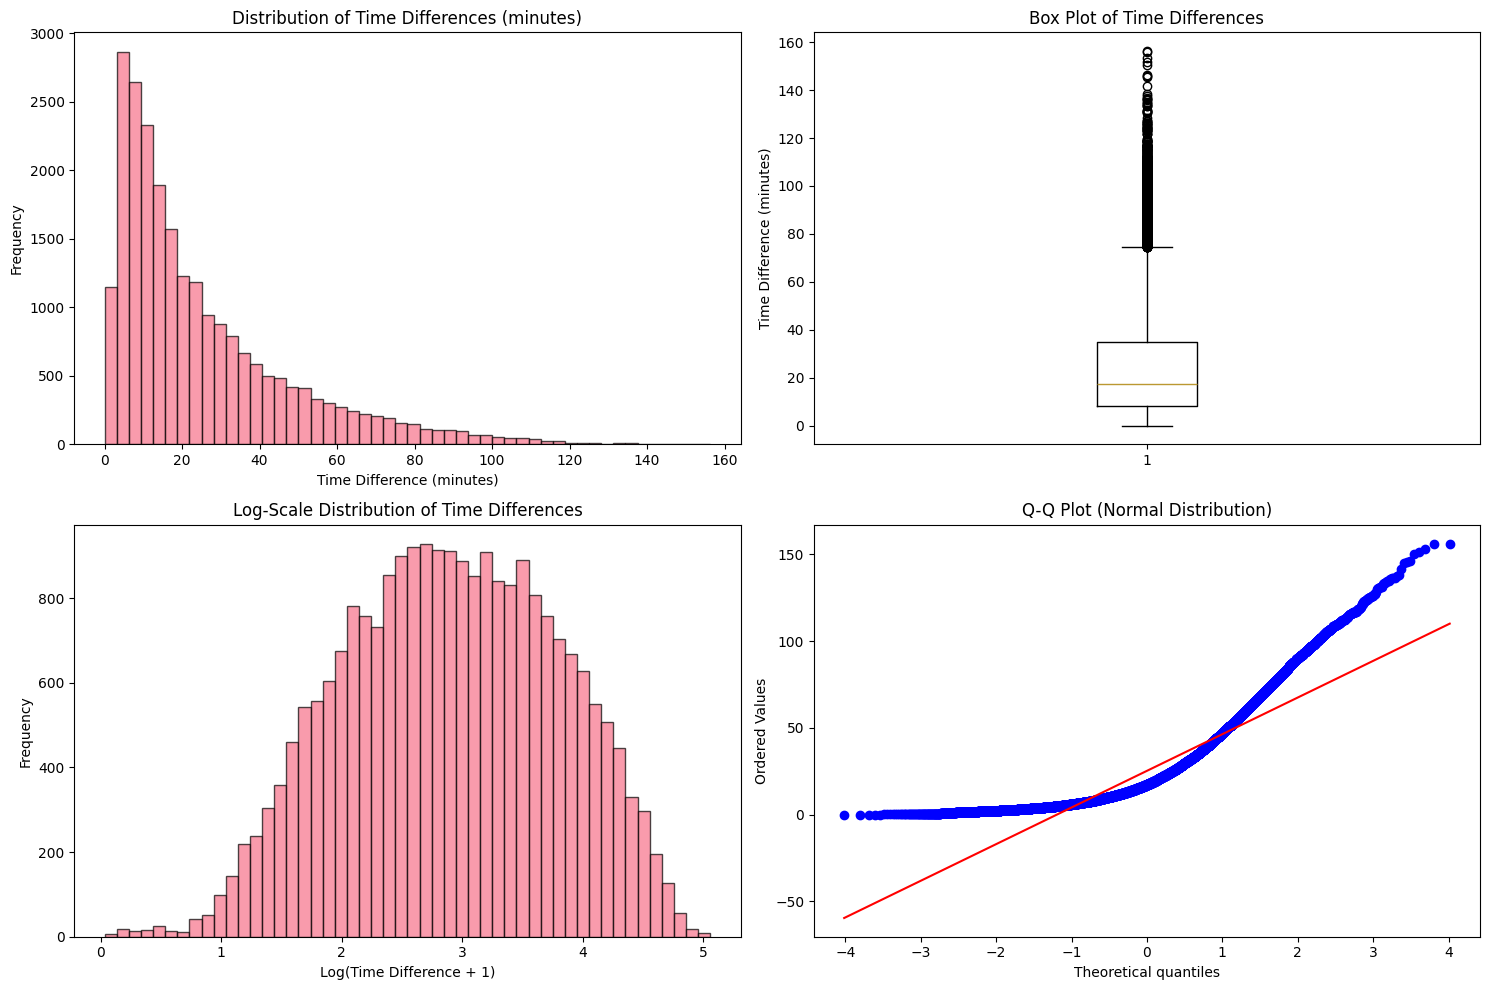


4. FEATURE AVAILABILITY AND QUALITY
Feature Analysis:

rating:
  type: numerical
  availability: 100.0%
  unique_values: 28
  mean: 1098.065920929041
  std: 372.5557167769124

oldRating:
  type: numerical
  availability: 100.0%
  unique_values: 1890
  mean: 1370.2538638886517
  std: 500.1144101426884

solveTime:
  type: numerical
  availability: 100.0%
  unique_values: 6817
  mean: 2514.2521987874647
  std: 2138.5319159283868

handle:
  type: categorical
  availability: 100.0%
  unique_values: 1138
  most_frequent: Nachia

contestId:
  type: categorical
  availability: 100.0%
  unique_values: 326
  most_frequent: 2123

problemIndex:
  type: categorical
  availability: 100.0%
  unique_values: 27
  most_frequent: A

problemName:
  type: categorical
  availability: 100.0%
  unique_values: 1266
  most_frequent: Add or XOR

tags:
  type: text
  availability: 100.0%
  unique_values: 671
  avg_tags_per_problem: 2.7682947656049866

5. CORRELATION ANALYSIS


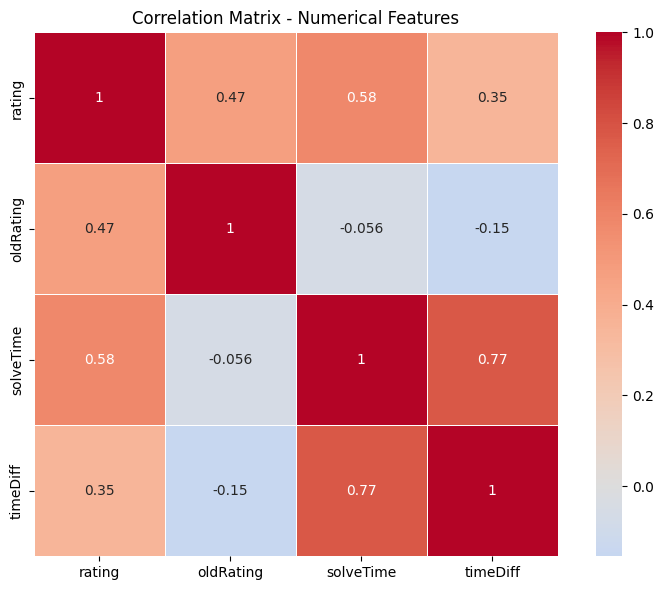

Correlations with timeDiff:
  solveTime: 0.773
  rating: 0.350
  oldRating: -0.155

6. FEATURE RELATIONSHIPS WITH TARGET


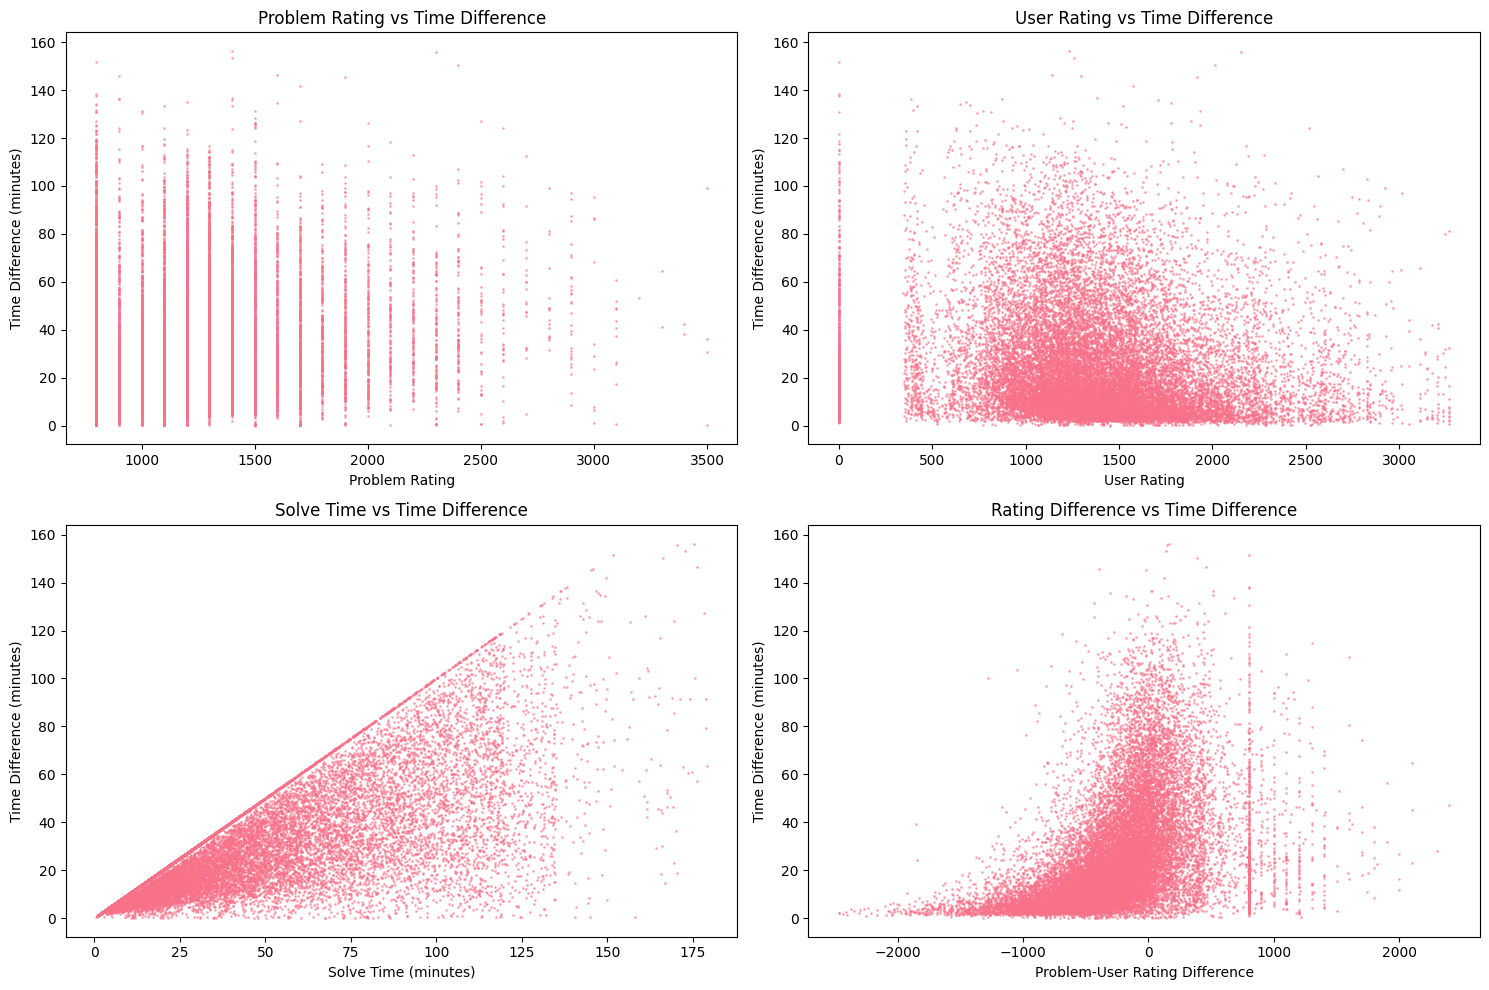


7. ML READINESS ASSESSMENT
✓ Sufficient samples (>1000): Yes (23422 samples)
✓ rating completeness (>80%): 100.0%
✓ oldRating completeness (>80%): 100.0%
✓ solveTime completeness (>80%): 100.0%
✓ tags completeness (>80%): 100.0%
✓ Target variable range: 156.3 minutes
✓ Target variable variance: 532.9
✓ Minimum class percentage (target binned): 20.0%

8. RECOMMENDATIONS FOR ML MODEL
STRENGTHS:
✓ Good sample size for training
✓ Key rating features have good completeness
✓ Some meaningful correlations exist

CHALLENGES:

RECOMMENDED PREPROCESSING:
1. Apply log transformation to target variable
2. Handle remaining outliers (beyond current filtering)
3. Feature engineering: rating differences, user experience metrics
4. One-hot encode tags or use text embeddings
5. Create temporal features from contest timing
6. Consider user-specific features (average solve times, etc.)

✓ OVERALL ASSESSMENT: GOOD
The dataset appears suitable for time difference prediction modeling.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('default')
sns.set_palette("husl")

print("=== EDA FOR TIME DIFFERENCE PREDICTION ===")
print(f"Dataset Shape: {df1.shape}")

# 1. DATA QUALITY ASSESSMENT
print("\n1. DATA QUALITY ASSESSMENT")
print("=" * 50)

# Missing values analysis
print("Missing Values:")
missing_info = df1.isnull().sum()
missing_pct = (missing_info / len(df1) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing_info,
    'Missing %': missing_pct
}).sort_values('Missing Count', ascending=False)
print(missing_df[missing_df['Missing Count'] > 0])

# Target variable (timeDiff) analysis
print(f"\nTarget Variable (timeDiff) Analysis:")
print(f"- Non-null count: {df1['timeDiff'].count()}")
print(f"- Null count: {df1['timeDiff'].isnull().sum()}")
print(f"- Data availability: {(df1['timeDiff'].count() / len(df1) * 100):.1f}%")

# 2. TARGET VARIABLE DISTRIBUTION
print("\n2. TARGET VARIABLE DISTRIBUTION")
print("=" * 50)

# Convert to minutes for better interpretability
df1_analysis = df1.copy()
df1_analysis['timeDiff_min'] = df1_analysis['timeDiff'] / 60

# Remove rows where timeDiff is null for analysis
df_clean = df1_analysis.dropna(subset=['timeDiff'])

print(f"Clean dataset size: {len(df_clean)} rows")
print(f"\nTimeDiff Statistics (in minutes):")
print(df_clean['timeDiff_min'].describe())

# Check for extreme outliers
Q1 = df_clean['timeDiff_min'].quantile(0.25)
Q3 = df_clean['timeDiff_min'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR
extreme_outliers = (df_clean['timeDiff_min'] > outlier_threshold).sum()
print(f"Extreme outliers (>Q3+1.5*IQR): {extreme_outliers} ({extreme_outliers/len(df_clean)*100:.1f}%)")

# 3. VISUALIZATION OF TARGET VARIABLE
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Histogram
axes[0,0].hist(df_clean['timeDiff_min'], bins=50, alpha=0.7, edgecolor='black')
axes[0,0].set_title('Distribution of Time Differences (minutes)')
axes[0,0].set_xlabel('Time Difference (minutes)')
axes[0,0].set_ylabel('Frequency')

# Box plot
axes[0,1].boxplot(df_clean['timeDiff_min'])
axes[0,1].set_title('Box Plot of Time Differences')
axes[0,1].set_ylabel('Time Difference (minutes)')

# Log scale histogram (to better see distribution)
axes[1,0].hist(np.log1p(df_clean['timeDiff_min']), bins=50, alpha=0.7, edgecolor='black')
axes[1,0].set_title('Log-Scale Distribution of Time Differences')
axes[1,0].set_xlabel('Log(Time Difference + 1)')
axes[1,0].set_ylabel('Frequency')

# QQ plot for normality
stats.probplot(df_clean['timeDiff_min'], dist="norm", plot=axes[1,1])
axes[1,1].set_title('Q-Q Plot (Normal Distribution)')

plt.tight_layout()
plt.show()

# 4. FEATURE AVAILABILITY AND QUALITY
print("\n4. FEATURE AVAILABILITY AND QUALITY")
print("=" * 50)

features_analysis = {}

# Numerical features
num_features = ['rating', 'oldRating', 'solveTime']
for feature in num_features:
    non_null = df_clean[feature].count()
    total = len(df_clean)
    availability = (non_null / total * 100)
    
    features_analysis[feature] = {
        'type': 'numerical',
        'availability': f"{availability:.1f}%",
        'unique_values': df_clean[feature].nunique(),
        'mean': df_clean[feature].mean(),
        'std': df_clean[feature].std()
    }

# Categorical features
cat_features = ['handle', 'contestId', 'problemIndex', 'problemName']
for feature in cat_features:
    non_null = df_clean[feature].count()
    total = len(df_clean)
    availability = (non_null / total * 100)
    
    features_analysis[feature] = {
        'type': 'categorical',
        'availability': f"{availability:.1f}%",
        'unique_values': df_clean[feature].nunique(),
        'most_frequent': df_clean[feature].mode().iloc[0] if len(df_clean[feature].mode()) > 0 else 'N/A'
    }

# Tags feature
tags_available = df_clean['tags'].notna().sum()
features_analysis['tags'] = {
    'type': 'text',
    'availability': f"{(tags_available/len(df_clean)*100):.1f}%",
    'unique_values': df_clean['tags'].nunique(),
    'avg_tags_per_problem': df_clean['tags'].str.count(',').mean() + 1
}

print("Feature Analysis:")
for feature, info in features_analysis.items():
    print(f"\n{feature}:")
    for key, value in info.items():
        print(f"  {key}: {value}")

# 5. CORRELATION ANALYSIS
print("\n5. CORRELATION ANALYSIS")
print("=" * 50)

# Numerical features correlation with target
numerical_cols = ['rating', 'oldRating', 'solveTime', 'timeDiff']
corr_matrix = df_clean[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5)
plt.title('Correlation Matrix - Numerical Features')
plt.tight_layout()
plt.show()

print("Correlations with timeDiff:")
correlations = corr_matrix['timeDiff'].drop('timeDiff').sort_values(key=abs, ascending=False)
for feature, corr in correlations.items():
    print(f"  {feature}: {corr:.3f}")

# 6. RELATIONSHIP VISUALIZATIONS
print("\n6. FEATURE RELATIONSHIPS WITH TARGET")
print("=" * 50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Problem rating vs timeDiff
axes[0,0].scatter(df_clean['rating'], df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[0,0].set_xlabel('Problem Rating')
axes[0,0].set_ylabel('Time Difference (minutes)')
axes[0,0].set_title('Problem Rating vs Time Difference')

# User rating vs timeDiff
axes[0,1].scatter(df_clean['oldRating'], df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[0,1].set_xlabel('User Rating')
axes[0,1].set_ylabel('Time Difference (minutes)')
axes[0,1].set_title('User Rating vs Time Difference')

# Solve time vs timeDiff
axes[1,0].scatter(df_clean['solveTime']/60, df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[1,0].set_xlabel('Solve Time (minutes)')
axes[1,0].set_ylabel('Time Difference (minutes)')
axes[1,0].set_title('Solve Time vs Time Difference')

# Rating difference vs timeDiff
df_clean['rating_diff'] = df_clean['rating'] - df_clean['oldRating']
axes[1,1].scatter(df_clean['rating_diff'], df_clean['timeDiff_min'], alpha=0.5, s=1)
axes[1,1].set_xlabel('Problem-User Rating Difference')
axes[1,1].set_ylabel('Time Difference (minutes)')
axes[1,1].set_title('Rating Difference vs Time Difference')

plt.tight_layout()
plt.show()

# 7. DATA QUALITY ASSESSMENT FOR ML
print("\n7. ML READINESS ASSESSMENT")
print("=" * 50)

# Check for sufficient data
min_samples = 1000
sufficient_data = len(df_clean) >= min_samples
print(f"✓ Sufficient samples (>{min_samples}): {'Yes' if sufficient_data else 'No'} ({len(df_clean)} samples)")

# Check feature completeness
feature_completeness = {}
for col in ['rating', 'oldRating', 'solveTime', 'tags']:
    completeness = (df_clean[col].count() / len(df_clean) * 100)
    feature_completeness[col] = completeness
    status = '✓' if completeness >= 80 else '✗'
    print(f"{status} {col} completeness (>80%): {completeness:.1f}%")

# Check target variable quality
target_range = df_clean['timeDiff_min'].max() - df_clean['timeDiff_min'].min()
target_variance = df_clean['timeDiff_min'].var()
print(f"✓ Target variable range: {target_range:.1f} minutes")
print(f"✓ Target variable variance: {target_variance:.1f}")

# Check for class imbalance (if we were to bin the target)
df_clean['timeDiff_bin'] = pd.qcut(df_clean['timeDiff_min'], q=5, labels=['Very Fast', 'Fast', 'Medium', 'Slow', 'Very Slow'])
class_distribution = df_clean['timeDiff_bin'].value_counts()
min_class_pct = (class_distribution.min() / len(df_clean) * 100)
print(f"✓ Minimum class percentage (target binned): {min_class_pct:.1f}%")

# 8. RECOMMENDATIONS
print("\n8. RECOMMENDATIONS FOR ML MODEL")
print("=" * 50)

print("STRENGTHS:")
if len(df_clean) >= 1000:
    print("✓ Good sample size for training")
if feature_completeness['rating'] >= 80 and feature_completeness['oldRating'] >= 80:
    print("✓ Key rating features have good completeness")
if abs(correlations['rating']) > 0.1 or abs(correlations['oldRating']) > 0.1:
    print("✓ Some meaningful correlations exist")

print("\nCHALLENGES:")
if df_clean['timeDiff_min'].skew() > 2:
    print("⚠ Highly skewed target variable - consider log transformation")
if extreme_outliers > len(df_clean) * 0.05:
    print("⚠ Many extreme outliers - consider additional outlier removal")
if feature_completeness['tags'] < 80:
    print("⚠ Tags feature has missing values - consider imputation or exclusion")

print("\nRECOMMENDED PREPROCESSING:")
print("1. Apply log transformation to target variable")
print("2. Handle remaining outliers (beyond current filtering)")
print("3. Feature engineering: rating differences, user experience metrics")
print("4. One-hot encode tags or use text embeddings")
print("5. Create temporal features from contest timing")
print("6. Consider user-specific features (average solve times, etc.)")

print(f"\n✓ OVERALL ASSESSMENT: {'GOOD' if sufficient_data and min(feature_completeness.values()) > 70 else 'NEEDS IMPROVEMENT'}")
print(f"The dataset appears {'suitable' if sufficient_data else 'insufficient'} for time difference prediction modeling.")

In [4]:
df1=df1.dropna()

=== SIMPLE XGBOOST WITH ONLY ONE-HOT ENCODING ===

1. DATA PREPARATION
Dataset size after removing null timeDiff: 23422
Applied log transformation to timeDiff

2. ONE-HOT ENCODING TAGS
Selected top 30 tags for one-hot encoding
Top tags: ['greedy', 'math', 'constructive algorithms', 'implementation', 'brute force', 'sortings', 'dp', 'data structures', 'binary search', 'bitmasks']...
Created 30 tag features

3. FEATURE PREPARATION
Basic features: ['rating', 'oldRating']
Tag features: 30 features
Total features: 32
Final dataset shape: X=(23422, 32), y=(23422,)

4. TRAIN-TEST SPLIT
Training set: (18737, 32)
Test set: (4685, 32)

5. XGBOOST HYPERPARAMETER TUNING
Starting hyperparameter tuning...
Fitting 5 folds for each of 128 candidates, totalling 640 fits
Best parameters: {'colsample_bytree': 0.9, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'reg_alpha': 1, 'reg_lambda': 2, 'subsample': 1.0}
Best CV score (RMSE): 0.7217

6. FINAL MODEL TRAINING

7. MODEL EVALUATION
Performa

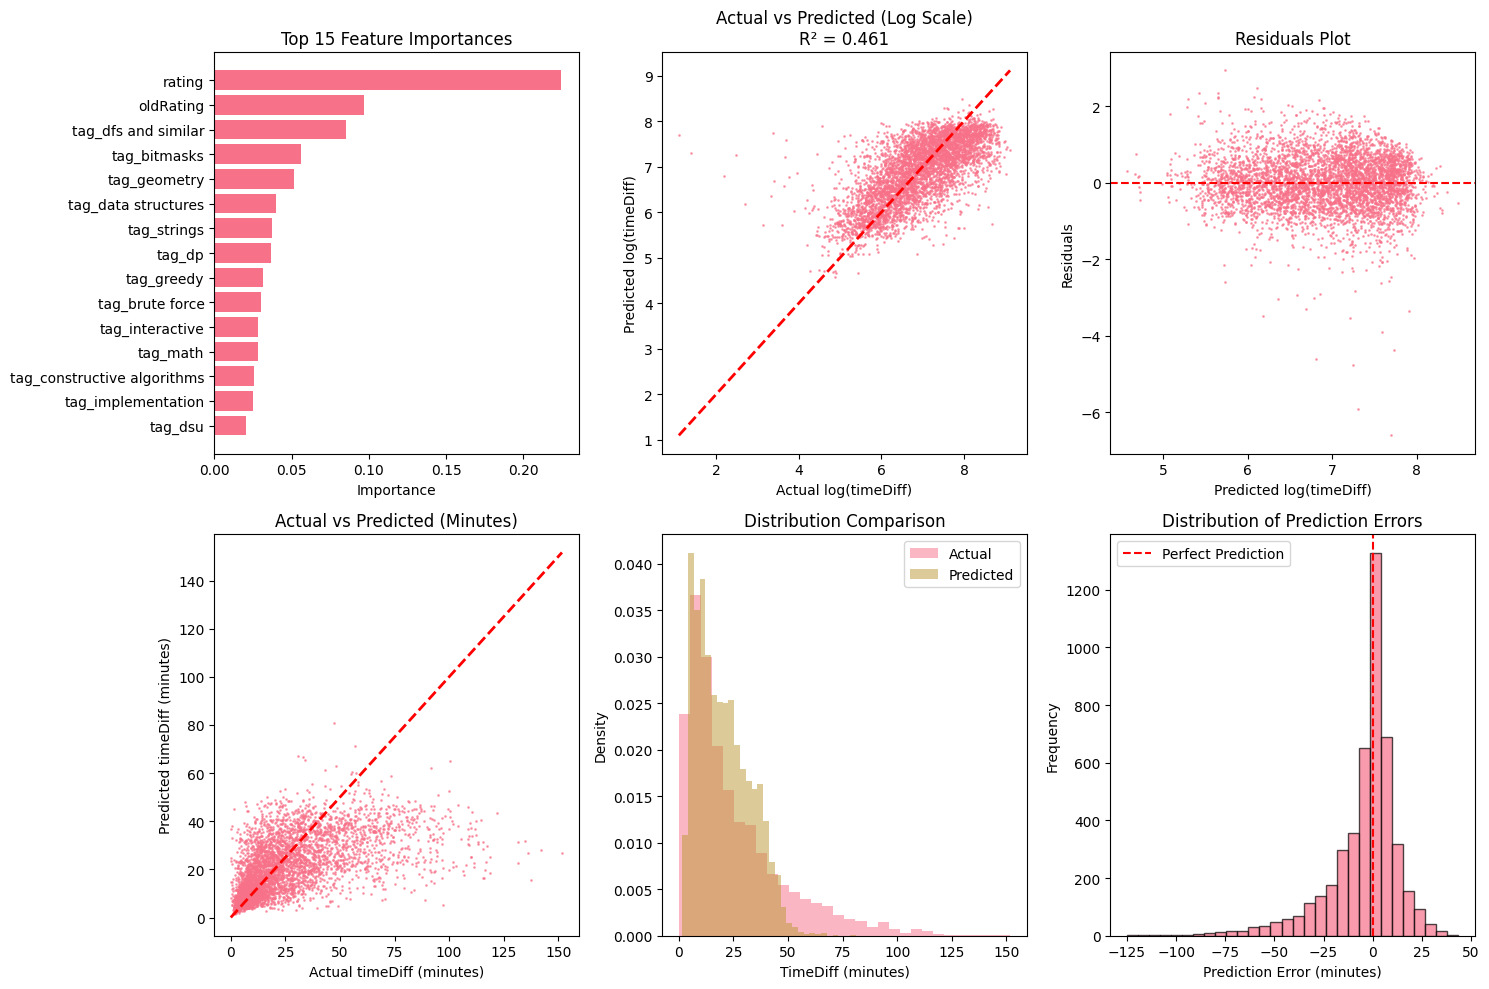


10. MODEL ANALYSIS
Number of features used: 32
- Basic numerical features: 2
- Tag features: 30

Model Performance Summary:
- Can explain 46.1% of variance in log(timeDiff)
- Average prediction error: 12.0 minutes
- Root mean squared error: 19.0 minutes
✓ Good generalization (train R² - test R² = 0.087)

11. SAVING MODEL
Model saved as 'simple_xgboost_timediff_model.json'
Model info saved as 'simple_model_info.json'

12. EXAMPLE PREDICTION
Sample prediction:
- Predicted timeDiff: 173 seconds (2.9 minutes)
- Actual timeDiff: 215 seconds (3.6 minutes)
- Error: 0.7 minutes

🎉 SIMPLE MODEL TRAINING COMPLETE!
Final Performance: R² = 0.461, RMSE = 19.0 minutes


In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("=== SIMPLE XGBOOST WITH ONLY ONE-HOT ENCODING ===")

# 1. DATA PREPARATION
print("\n1. DATA PREPARATION")
print("=" * 50)

# Remove rows with missing timeDiff (our target)
df_model = df1.dropna(subset=['timeDiff']).copy()
print(f"Dataset size after removing null timeDiff: {len(df_model)}")

# Apply log transformation to target variable
df_model['log_timeDiff'] = np.log1p(df_model['timeDiff'])
print(f"Applied log transformation to timeDiff")

# 2. ONE-HOT ENCODE TAGS ONLY
print("\n2. ONE-HOT ENCODING TAGS")
print("=" * 50)

# Get all unique tags and their frequencies
tag_counts = {}
for tags_str in df_model['tags'].dropna():
    if isinstance(tags_str, str) and tags_str.strip():
        tag_list = [tag.strip() for tag in tags_str.split(',')]
        for tag in tag_list:
            if tag and tag != '':
                tag_counts[tag] = tag_counts.get(tag, 0) + 1

# Select top 30 most frequent tags (to avoid too many features)
top_tags = sorted(tag_counts.items(), key=lambda x: x[1], reverse=True)[:30]
selected_tags = [tag for tag, count in top_tags]
print(f"Selected top {len(selected_tags)} tags for one-hot encoding")
print(f"Top tags: {selected_tags[:10]}...")

# Create one-hot encoding for selected tags
for tag in selected_tags:
    df_model[f'tag_{tag}'] = df_model['tags'].apply(
        lambda x: 1 if isinstance(x, str) and tag in [t.strip() for t in x.split(',')] else 0
    )

print(f"Created {len(selected_tags)} tag features")

# 3. PREPARE FEATURES
print("\n3. FEATURE PREPARATION")
print("=" * 50)

# Use only basic numerical features + one-hot encoded tags
# Exclude: timeDiff, log_timeDiff, solveTime, handle, contestId, problemIndex, problemName, tags
basic_features = ['rating', 'oldRating']
tag_features = [f'tag_{tag}' for tag in selected_tags]
feature_cols = basic_features + tag_features

print(f"Basic features: {basic_features}")
print(f"Tag features: {len(tag_features)} features")
print(f"Total features: {len(feature_cols)}")

# Prepare X and y
X = df_model[feature_cols].copy()
y = df_model['log_timeDiff'].copy()

# Handle missing values in basic features
for col in basic_features:
    if X[col].isnull().sum() > 0:
        median_val = X[col].median()
        X[col] = X[col].fillna(median_val)
        print(f"Filled {X[col].isnull().sum()} missing values in {col} with median: {median_val}")

print(f"Final dataset shape: X={X.shape}, y={y.shape}")

# 4. TRAIN-TEST SPLIT
print("\n4. TRAIN-TEST SPLIT")
print("=" * 50)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

# 5. XGBOOST HYPERPARAMETER TUNING
print("\n5. XGBOOST HYPERPARAMETER TUNING")
print("=" * 50)

# Define parameter grid for tuning
param_grid = {
    'n_estimators': [200, 300],
    'max_depth': [6, 9],
    'learning_rate': [0.1, 0.2],
    'subsample': [0.9, 1.0],
    'colsample_bytree': [0.9, 1.0],
    'reg_alpha': [0.1, 1],
    'reg_lambda': [1.5, 2]
}

print("Starting hyperparameter tuning...")
xgb_model = xgb.XGBRegressor(
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

# Grid search with cross-validation
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV score (RMSE): {np.sqrt(-grid_search.best_score_):.4f}")

# 6. TRAIN FINAL MODEL
print("\n6. FINAL MODEL TRAINING")
print("=" * 50)

final_model = grid_search.best_estimator_
final_model.fit(X_train, y_train)

# 7. MODEL EVALUATION
print("\n7. MODEL EVALUATION")
print("=" * 50)

# Predictions
y_train_pred = final_model.predict(X_train)
y_test_pred = final_model.predict(X_test)

# Convert back from log scale for interpretation
y_train_actual = np.expm1(y_train)  # exp(x) - 1 to reverse log1p
y_test_actual = np.expm1(y_test)
y_train_pred_actual = np.expm1(y_train_pred)
y_test_pred_actual = np.expm1(y_test_pred)

# Metrics in log scale
train_rmse_log = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse_log = np.sqrt(mean_squared_error(y_test, y_test_pred))
train_mae_log = mean_absolute_error(y_train, y_train_pred)
test_mae_log = mean_absolute_error(y_test, y_test_pred)
train_r2_log = r2_score(y_train, y_train_pred)
test_r2_log = r2_score(y_test, y_test_pred)

# Metrics in original scale (seconds)
train_rmse_orig = np.sqrt(mean_squared_error(y_train_actual, y_train_pred_actual))
test_rmse_orig = np.sqrt(mean_squared_error(y_test_actual, y_test_pred_actual))
train_mae_orig = mean_absolute_error(y_train_actual, y_train_pred_actual)
test_mae_orig = mean_absolute_error(y_test_actual, y_test_pred_actual)

print("Performance Metrics:")
print(f"{'Metric':<20} {'Train':<15} {'Test':<15}")
print(f"{'-'*50}")
print(f"{'RMSE (log scale)':<20} {train_rmse_log:<15.4f} {test_rmse_log:<15.4f}")
print(f"{'MAE (log scale)':<20} {train_mae_log:<15.4f} {test_mae_log:<15.4f}")
print(f"{'R² (log scale)':<20} {train_r2_log:<15.4f} {test_r2_log:<15.4f}")
print(f"{'RMSE (seconds)':<20} {train_rmse_orig:<15.0f} {test_rmse_orig:<15.0f}")
print(f"{'MAE (seconds)':<20} {train_mae_orig:<15.0f} {test_mae_orig:<15.0f}")

# 8. FEATURE IMPORTANCE
print("\n8. FEATURE IMPORTANCE")
print("=" * 50)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 15 Most Important Features:")
print(feature_importance.head(15).to_string(index=False))

# 9. VISUALIZATIONS
plt.figure(figsize=(15, 10))

# Feature Importance Plot
plt.subplot(2, 3, 1)
top_features = feature_importance.head(15)
plt.barh(range(len(top_features)), top_features['importance'])
plt.yticks(range(len(top_features)), top_features['feature'])
plt.title('Top 15 Feature Importances')
plt.xlabel('Importance')
plt.gca().invert_yaxis()

# Actual vs Predicted (log scale)
plt.subplot(2, 3, 2)
plt.scatter(y_test, y_test_pred, alpha=0.6, s=1)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual log(timeDiff)')
plt.ylabel('Predicted log(timeDiff)')
plt.title(f'Actual vs Predicted (Log Scale)\nR² = {test_r2_log:.3f}')

# Residuals Plot
plt.subplot(2, 3, 3)
residuals = y_test - y_test_pred
plt.scatter(y_test_pred, residuals, alpha=0.6, s=1)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted log(timeDiff)')
plt.ylabel('Residuals')
plt.title('Residuals Plot')

# Actual vs Predicted (original scale, in minutes)
plt.subplot(2, 3, 4)
plt.scatter(y_test_actual/60, y_test_pred_actual/60, alpha=0.6, s=1)
plt.plot([y_test_actual.min()/60, y_test_actual.max()/60], 
         [y_test_actual.min()/60, y_test_actual.max()/60], 'r--', lw=2)
plt.xlabel('Actual timeDiff (minutes)')
plt.ylabel('Predicted timeDiff (minutes)')
plt.title('Actual vs Predicted (Minutes)')

# Distribution comparison
plt.subplot(2, 3, 5)
plt.hist(y_test_actual/60, bins=30, alpha=0.5, label='Actual', density=True)
plt.hist(y_test_pred_actual/60, bins=30, alpha=0.5, label='Predicted', density=True)
plt.xlabel('TimeDiff (minutes)')
plt.ylabel('Density')
plt.title('Distribution Comparison')
plt.legend()

# Error distribution
plt.subplot(2, 3, 6)
errors = (y_test_pred_actual - y_test_actual) / 60  # Error in minutes
plt.hist(errors, bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Prediction Error (minutes)')
plt.ylabel('Frequency')
plt.title('Distribution of Prediction Errors')
plt.axvline(x=0, color='r', linestyle='--', label='Perfect Prediction')
plt.legend()

plt.tight_layout()
plt.show()

# 10. MODEL ANALYSIS
print("\n10. MODEL ANALYSIS")
print("=" * 50)

print(f"Number of features used: {len(feature_cols)}")
print(f"- Basic numerical features: {len(basic_features)}")
print(f"- Tag features: {len(tag_features)}")

print(f"\nModel Performance Summary:")
print(f"- Can explain {test_r2_log:.1%} of variance in log(timeDiff)")
print(f"- Average prediction error: {test_mae_orig/60:.1f} minutes")
print(f"- Root mean squared error: {test_rmse_orig/60:.1f} minutes")

# Check if model is overfitting
overfitting_score = train_r2_log - test_r2_log
if overfitting_score > 0.1:
    print(f"⚠ Potential overfitting detected (train R² - test R² = {overfitting_score:.3f})")
else:
    print(f"✓ Good generalization (train R² - test R² = {overfitting_score:.3f})")

# 11. SAVE MODEL
print("\n11. SAVING MODEL")
print("=" * 50)

# Save the model
final_model.save_model('simple_xgboost_timediff_model.json')
print("Model saved as 'simple_xgboost_timediff_model.json'")

# Save feature information
model_info = {
    'features_used': feature_cols,
    'basic_features': basic_features,
    'tag_features': tag_features,
    'selected_tags': selected_tags,
    'best_parameters': grid_search.best_params_,
    'performance_metrics': {
        'test_r2_log': test_r2_log,
        'test_rmse_log': test_rmse_log,
        'test_mae_seconds': test_mae_orig,
        'test_rmse_seconds': test_rmse_orig
    },
    'feature_importance': feature_importance.head(20).to_dict('records')
}

import json
with open('simple_model_info.json', 'w') as f:
    json.dump(model_info, f, indent=2)
print("Model info saved as 'simple_model_info.json'")

# 12. PREDICTION EXAMPLE
print("\n12. EXAMPLE PREDICTION")
print("=" * 50)

# Show how to make predictions on new data
sample_idx = 0
sample_features = X_test.iloc[sample_idx:sample_idx+1]
sample_prediction_log = final_model.predict(sample_features)[0]
sample_prediction_seconds = np.expm1(sample_prediction_log)
actual_seconds = np.expm1(y_test.iloc[sample_idx])

print(f"Sample prediction:")
print(f"- Predicted timeDiff: {sample_prediction_seconds:.0f} seconds ({sample_prediction_seconds/60:.1f} minutes)")
print(f"- Actual timeDiff: {actual_seconds:.0f} seconds ({actual_seconds/60:.1f} minutes)")
print(f"- Error: {abs(sample_prediction_seconds - actual_seconds)/60:.1f} minutes")

print(f"\n🎉 SIMPLE MODEL TRAINING COMPLETE!")
print(f"Final Performance: R² = {test_r2_log:.3f}, RMSE = {test_rmse_orig/60:.1f} minutes")

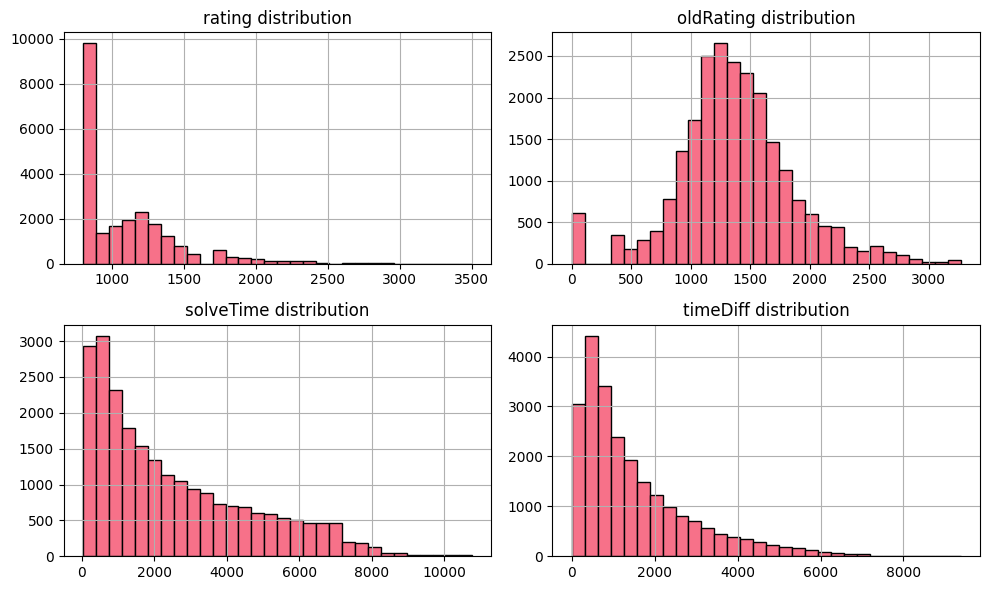

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your dataset
df = pd.read_csv("processed_codeforces_data.csv")  # change to your actual file path

# Pick only numeric independent variables
numeric_features = ["rating", "oldRating", "solveTime", "timeDiff"]

# Plot histograms for each numeric feature
plt.figure(figsize=(10, 6))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(2, 2, i)
    df[col].hist(bins=30, edgecolor='black')
    plt.title(f"{col} distribution")
plt.tight_layout()
plt.show()


Counts per (user_bin x rating_bin) BEFORE balancing (showing nonzero cells):
user_bin   rating_bin
1000-1199  800-999       2767.0
1200-1399  800-999       2642.0
1400-1599  800-999       1998.0
800-999    800-999       1835.0
1200-1399  1000-1199     1061.0
1600-1799  800-999       1036.0
1400-1599  1000-1199      859.0
1000-1199  1000-1199      778.0
1400-1599  1200-1399      761.0
1200-1399  1200-1399      680.0
600-799    800-999        663.0
1600-1799  1000-1199      528.0
           1200-1399      517.0
1800-1999  800-999        502.0
0-199      800-999        453.0
1000-1199  1200-1399      336.0
1400-1599  1400-1599      324.0
400-599    800-999        311.0
1800-1999  1000-1199      257.0
           1200-1399      251.0
1600-1799  1400-1599      240.0
2000-2199  800-999        239.0
800-999    1000-1199      238.0
1600-1799  1600-1799      209.0
1400-1599  1600-1799      199.0
1200-1399  1400-1599      181.0
200-399    800-999        167.0
1800-1999  1600-1799      153.0
2000-

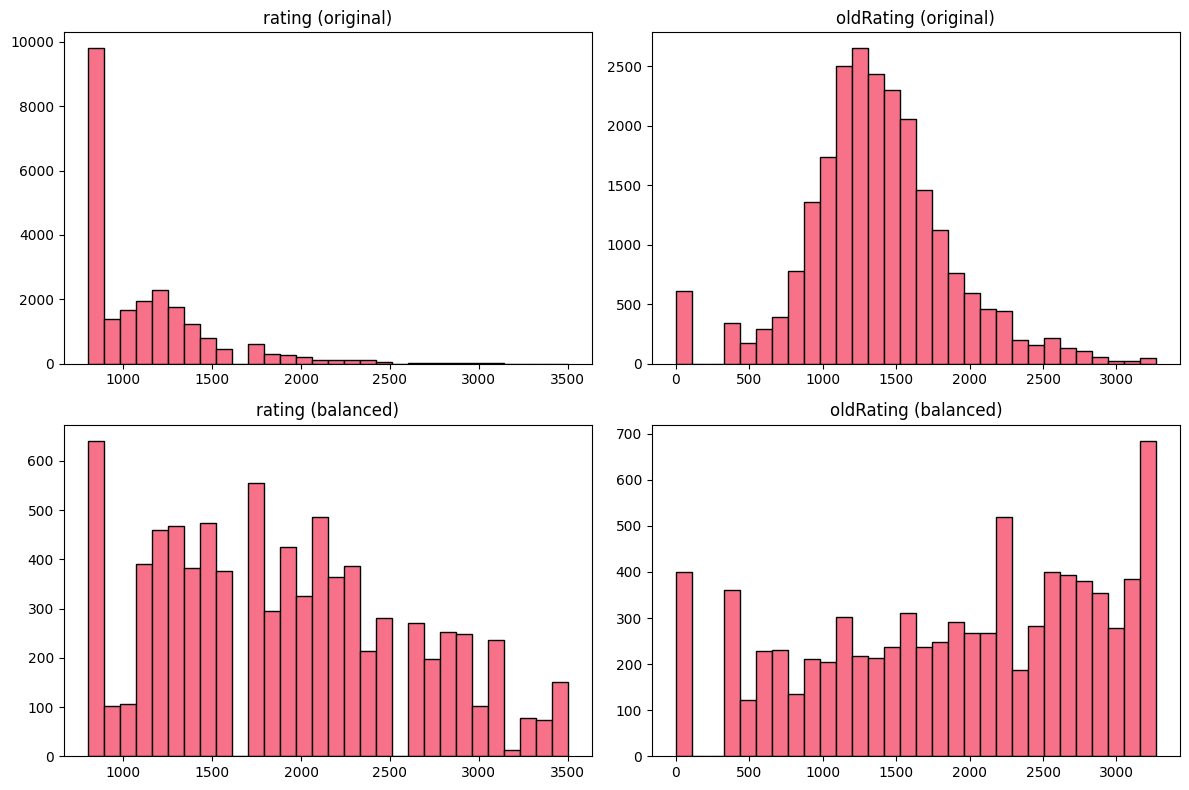

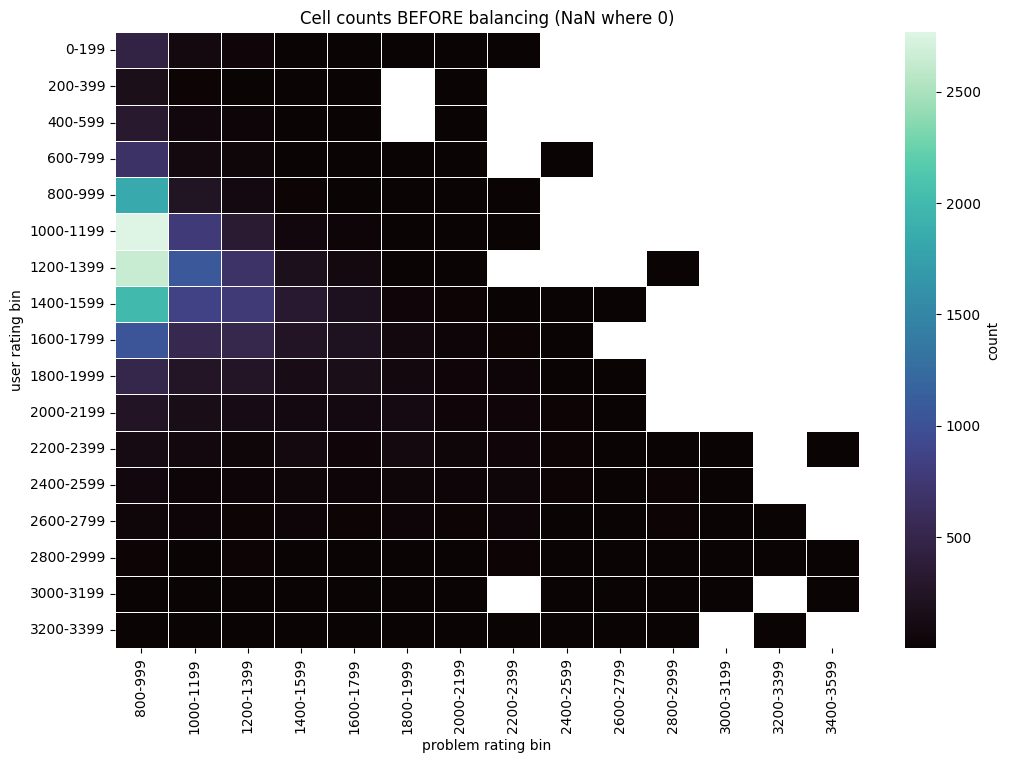


Train/test split done. Train=6680, Test=1670

Summary: {'original_rows': 23422, 'balanced_rows': 8350, 'unique_cells_before': 167, 'unique_cells_after': 167}


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ---- PARAMETERS ----
STEP = 200                 # bin width for ratings
MIN_FLOOR = 800            # lowest bin floor (Codeforces typical)
target_per_cell = 50       # desired rows per (user_bin, problem_bin) cell
random_state = 42
# ---------------------

# assume df is already loaded in your session and named `df`
df = df.copy()

# Ensure numeric ratings
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['oldRating'] = pd.to_numeric(df['oldRating'], errors='coerce')

# Drop rows missing either rating or oldRating (you can keep if you prefer)
df = df.dropna(subset=['rating', 'oldRating']).reset_index(drop=True)

# Helper to build bins and labels
def make_bins_for_col(series, step=STEP, floor=MIN_FLOOR):
    mn = int(np.floor(series.min() / step) * step)
    mx = int(np.ceil(series.max() / step) * step)
    start = min(mn, floor)
    end = mx
    bins = np.arange(start, end + step, step)
    labels = [f"{b}-{b+step-1}" for b in bins[:-1]]
    return bins, labels

# Create rating bins
bins_r, labels_r = make_bins_for_col(df['rating'])
df['rating_bin'] = pd.cut(df['rating'], bins=bins_r, labels=labels_r, include_lowest=True)

# Create user (oldRating) bins
bins_u, labels_u = make_bins_for_col(df['oldRating'])
df['user_bin'] = pd.cut(df['oldRating'], bins=bins_u, labels=labels_u, include_lowest=True)

# Quick check: how many rows per cell before balancing
cell_counts_before = df.groupby(['user_bin', 'rating_bin']).size().unstack(fill_value=0)
print("Counts per (user_bin x rating_bin) BEFORE balancing (showing nonzero cells):")
print(cell_counts_before[cell_counts_before > 0].stack().sort_values(ascending=False).head(30))

# Build balanced dataset by sampling each cell to target_per_cell
sampled_rows = []
missing_cells = 0
for (ub, rb), group in df.groupby(['user_bin', 'rating_bin']):
    n = len(group)
    if n == 0 or pd.isna(ub) or pd.isna(rb):
        missing_cells += 1
        continue
    if n >= target_per_cell:
        sampled = group.sample(n=target_per_cell, replace=False, random_state=random_state)
    else:
        # upsample with replacement when not enough rows
        sampled = group.sample(n=target_per_cell, replace=True, random_state=random_state)
    sampled_rows.append(sampled)

if len(sampled_rows) == 0:
    raise ValueError("No cells were sampled — check your rating columns and bins.")

df_bal = pd.concat(sampled_rows).reset_index(drop=True)
print(f"\nBalanced dataset created with target_per_cell={target_per_cell}.")
print(f"Original rows used (unique rows may be duplicated due to upsampling): {len(df_bal)}")
if missing_cells:
    print(f"Skipped {missing_cells} empty/missing cells.")

# Check counts after balancing
cell_counts_after = df_bal.groupby(['user_bin', 'rating_bin']).size().unstack(fill_value=0)
print("\nCounts per (user_bin x rating_bin) AFTER balancing (showing a few cells):")
print(cell_counts_after.stack().sort_index().head(20))

# Plot marginal histograms before vs after (rating and oldRating)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].hist(df['rating'], bins=30, edgecolor='black')
axes[0,0].set_title('rating (original)')

axes[0,1].hist(df['oldRating'], bins=30, edgecolor='black')
axes[0,1].set_title('oldRating (original)')

axes[1,0].hist(df_bal['rating'], bins=30, edgecolor='black')
axes[1,0].set_title('rating (balanced)')

axes[1,1].hist(df_bal['oldRating'], bins=30, edgecolor='black')
axes[1,1].set_title('oldRating (balanced)')

plt.tight_layout()
plt.show()

# Optional: inspect per-cell counts heatmap (large grids may need resizing)
try:
    import seaborn as sns
    plt.figure(figsize=(12,8))
    sns.heatmap(cell_counts_before.replace(0, np.nan), cmap='mako', cbar_kws={'label':'count'}, linewidths=0.5)
    plt.title('Cell counts BEFORE balancing (NaN where 0)')
    plt.xlabel('problem rating bin')
    plt.ylabel('user rating bin')
    plt.show()
except Exception:
    pass

# OPTIONAL: stratified train/test split by combined cell label
df_bal['cell'] = df_bal['user_bin'].astype(str) + '___' + df_bal['rating_bin'].astype(str)
train_df, test_df = train_test_split(df_bal, test_size=0.2, random_state=random_state, stratify=df_bal['cell'])
print(f"\nTrain/test split done. Train={len(train_df)}, Test={len(test_df)}")

# Save balanced dataset if you want
# df_bal.to_csv("balanced_dataset.csv", index=False)

# Summary output
summary = {
    'original_rows': len(df),
    'balanced_rows': len(df_bal),
    'unique_cells_before': int((cell_counts_before>0).sum().sum()),
    'unique_cells_after': int((cell_counts_after>0).sum().sum())
}
print("\nSummary:", summary)


In [16]:
df.head()

,handle,contestId,problemIndex,problemName,rating,oldRating,tags,solveTime,timeDiff,rating_bin,user_bin
0,Nachia,2029,G,Balanced Problem,3000.0,3151.0,"data structures, dp",5483,1418,2800-2999,3000-3199
1,Nachia,2029,F,Palindrome Everywhere,2500.0,3151.0,"constructive algorithms, graphs, greedy",4065,899,2400-2599,3000-3199
2,Nachia,2029,E,Common Generator,2100.0,3151.0,"brute force, constructive algorithms, math, nu...",3166,1453,2000-2199,3000-3199
3,Nachia,2029,D,Cool Graph,1900.0,3151.0,"constructive algorithms, data structures, dfs ...",1713,1164,1800-1999,3000-3199
4,Nachia,2029,C,New Rating,1700.0,3151.0,"binary search, data structures, dp, greedy",549,207,1600-1799,3000-3199


Shapes -> X_train: (6012, 22), X_val: (668, 22), X_test: (1670, 22)
Using features: ['rating', 'oldRating', 'diff', 'tag_constructive algorithms', 'tag_binary search', 'tag_brute force', 'tag_combinatorics', 'tag_data structures', 'tag_bitmasks', 'tag_greedy', 'tag_dp', 'tag_dfs and similar', 'tag_geometry', 'tag_implementation', 'tag_math', 'tag_2-sat', 'tag_graphs', 'tag_games', 'tag_chinese remainder theorem', 'tag_strings', 'tag_graph matchings', 'tag_hashing']
Saved model -> xgb_balanced_timediff.json
Saved features+scaler -> xgb_features.pkl
--- Train metrics ---
RMSE (log): 0.3211 | MAE (log): 0.1824 | R2 (log): 0.9080
RMSE (seconds): 615.6 | MAE (seconds): 311.9 | MAE (minutes): 5.20
--- Test metrics ---
RMSE (log): 0.5251 | MAE (log): 0.2934 | R2 (log): 0.7624
RMSE (seconds): 903.4 | MAE (seconds): 468.5 | MAE (minutes): 7.81


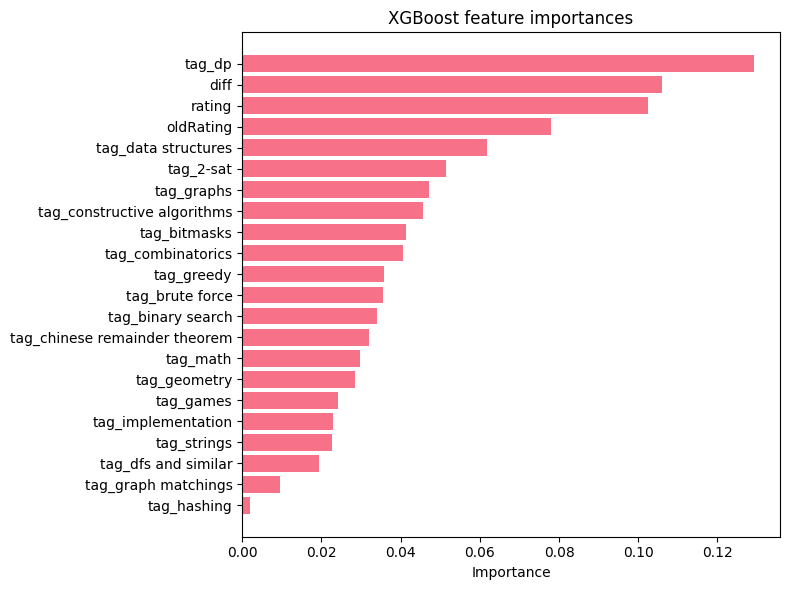

Top features:
                      feature  importance
                       tag_dp    0.129342
                         diff    0.106020
                       rating    0.102472
                    oldRating    0.078036
          tag_data structures    0.061803
                    tag_2-sat    0.051464
                   tag_graphs    0.047206
  tag_constructive algorithms    0.045727
                 tag_bitmasks    0.041367
            tag_combinatorics    0.040533
                   tag_greedy    0.035911
              tag_brute force    0.035444
            tag_binary search    0.034008
tag_chinese remainder theorem    0.031995
                     tag_math    0.029696
                 tag_geometry    0.028417
                    tag_games    0.024076
           tag_implementation    0.022953
                  tag_strings    0.022796
          tag_dfs and similar    0.019421
Saved test predictions to xgb_test_predictions.csv


In [18]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt
import joblib

# ----------------------------
# PARAMETERS
# ----------------------------
TOP_TAGS = 30           # top-K primary tags to one-hot
RNG = 42
XGB_PARAMS = {
    "n_estimators": 1000,
    "learning_rate": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.5,
    "random_state": RNG,
    "n_jobs": -1,
    "verbosity": 0
}
EARLY_STOPPING_ROUNDS = 50
VALID_FRAC = 0.1   # fraction of train used as XGB validation (for early stopping)
MODEL_PATH = "xgb_balanced_timediff.json"
FEATURES_PATH = "xgb_features.pkl"

# ----------------------------
# FUNCTION: create features
# ----------------------------
def prepare_features(df, top_tags=None, fit_scaler=None):
    df = df.copy()
    # numeric features
    # ensure rating columns exist
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
    df['oldRating'] = pd.to_numeric(df['oldRating'], errors='coerce')
    df['diff'] = df['rating'] - df['oldRating']
    
    # continuous features to use (you can add more)
    numeric_cols = ['rating', 'oldRating', 'diff']
    
    # tags: use primary tag (first tag) then top-K one-hot
    df['primary_tag'] = df['tags'].apply(lambda s: s.split(',')[0].strip() if isinstance(s, str) and s.strip() else 'unknown')
    if top_tags is None:
        top_tags = df['primary_tag'].value_counts().nlargest(TOP_TAGS).index.tolist()
    # make one-hot columns for top tags
    for tag in top_tags:
        df[f"tag_{tag}"] = (df['primary_tag'] == tag).astype(int)
    tag_cols = [f"tag_{t}" for t in top_tags]
    
    # target: log transform already present? use 'log_timeDiff' else create
    if 'log_timeDiff' not in df.columns:
        if 'timeDiff' in df.columns:
            df['log_timeDiff'] = np.log1p(df['timeDiff'])
        else:
            raise ValueError("No timeDiff column found to create log_timeDiff.")
    
    # scaler for numeric features (fit on training only)
    if fit_scaler is None:
        scaler = StandardScaler()
        df[numeric_cols] = scaler.fit_transform(df[numeric_cols].fillna(0))
    else:
        scaler = fit_scaler
        df[numeric_cols] = scaler.transform(df[numeric_cols].fillna(0))
    
    feature_cols = numeric_cols + tag_cols
    X = df[feature_cols].fillna(0)
    y = df['log_timeDiff']
    return X, y, feature_cols, scaler, top_tags

# ----------------------------
# PREP: prepare train/val/test
# ----------------------------
# If you used the earlier script, you already have train_df/test_df
# Otherwise, you can split df_bal: train/test = 80/20 stratified by `cell` or random
if 'train_df' not in globals() or 'test_df' not in globals():
    # fallback: simple random split from df_bal
    from sklearn.model_selection import train_test_split
    train_df, test_df = train_test_split(df_bal, test_size=0.2, random_state=RNG, shuffle=True)

# Prepare train features (fit scaler here)
X_train_full, y_train_full, feature_cols, scaler, top_tags = prepare_features(train_df)
X_test, y_test, _, _, _ = prepare_features(test_df, top_tags=top_tags, fit_scaler=scaler)

# Create a small validation set from the training data for early stopping
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=VALID_FRAC, random_state=RNG)

print(f"Shapes -> X_train: {X_train.shape}, X_val: {X_val.shape}, X_test: {X_test.shape}")
print("Using features:", feature_cols)

# ----------------------------
# XGBoost training with early stopping
# ----------------------------
model = xgb.XGBRegressor(**XGB_PARAMS)

model.fit(
    X_train, y_train,

)

# Save model and feature list + scaler
model.save_model(MODEL_PATH)
joblib.dump({"features": feature_cols, "scaler": scaler, "top_tags": top_tags}, FEATURES_PATH)
print(f"Saved model -> {MODEL_PATH}")
print(f"Saved features+scaler -> {FEATURES_PATH}")

# ----------------------------
# EVALUATION
# ----------------------------
def evaluate_and_print(model, X, y, label="Test"):
    y_pred_log = model.predict(X)
    # metrics on log scale
    rmse_log = np.sqrt(mean_squared_error(y, y_pred_log))
    mae_log  = mean_absolute_error(y, y_pred_log)
    r2_log   = r2_score(y, y_pred_log)
    # convert to original seconds
    y_actual = np.expm1(y)
    y_pred_seconds = np.expm1(y_pred_log)
    rmse_orig = np.sqrt(mean_squared_error(y_actual, y_pred_seconds))
    mae_orig  = mean_absolute_error(y_actual, y_pred_seconds)
    print(f"--- {label} metrics ---")
    print(f"RMSE (log): {rmse_log:.4f} | MAE (log): {mae_log:.4f} | R2 (log): {r2_log:.4f}")
    print(f"RMSE (seconds): {rmse_orig:.1f} | MAE (seconds): {mae_orig:.1f} | MAE (minutes): {mae_orig/60:.2f}")
    return {"rmse_log": rmse_log, "mae_log": mae_log, "r2_log": r2_log, "rmse_orig": rmse_orig, "mae_orig": mae_orig}

train_metrics = evaluate_and_print(model, X_train_full, y_train_full, label="Train")
test_metrics = evaluate_and_print(model, X_test, y_test, label="Test")

# ----------------------------
# Feature importance plot (gain)
# ----------------------------
fi = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8,6))
plt.barh(fi['feature'].values[::-1], fi['importance'].values[::-1])
plt.title("XGBoost feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("Top features:")
print(fi.head(20).to_string(index=False))

# ----------------------------
# Optional: save predictions on test set
# ----------------------------
test_preds_log = model.predict(X_test)
test_preds_seconds = np.expm1(test_preds_log)
out = test_df.copy().reset_index(drop=True)
out['pred_log_timeDiff'] = test_preds_log
out['pred_timeDiff_seconds'] = test_preds_seconds
out['actual_timeDiff_seconds'] = np.expm1(y_test.reset_index(drop=True))
out[['handle','contestId','problemIndex','rating','oldRating','tags','actual_timeDiff_seconds','pred_timeDiff_seconds']].head(10)

# Save predictions CSV if desired
out.to_csv("xgb_test_predictions.csv", index=False)
print("Saved test predictions to xgb_test_predictions.csv")


In [ ]:
# RandomizedSearchCV hyperparameter tuning for XGBoost (on log target)
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import joblib
from scipy.stats import randint, uniform
from sklearn.preprocessing import StandardScaler

RNG = 42
N_ITER = 30       # increase for more thorough search
CV = 3            # cross-validation folds
N_JOBS = -1

# ------------------------
# prepare_features (same as before)
# ------------------------
TOP_TAGS = 30
def prepare_features(df, top_tags=None, fit_scaler=None):
    df = df.copy()
    df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
    df['oldRating'] = pd.to_numeric(df['oldRating'], errors='coerce')
    df['diff'] = df['rating'] - df['oldRating']
    numeric_cols = ['rating', 'oldRating', 'diff']
    df['primary_tag'] = df['tags'].apply(lambda s: s.split(',')[0].strip() if isinstance(s, str) and s.strip() else 'unknown')
    if top_tags is None:
        top_tags = df['primary_tag'].value_counts().nlargest(TOP_TAGS).index.tolist()
    for tag in top_tags:
        df[f"tag_{tag}"] = (df['primary_tag'] == tag).astype(int)
    tag_cols = [f"tag_{t}" for t in top_tags]
    if 'log_timeDiff' not in df.columns:
        if 'timeDiff' in df.columns:
            df['log_timeDiff'] = np.log1p(df['timeDiff'])
        else:
            raise ValueError("No timeDiff column found to create log_timeDiff.")
    if fit_scaler is None:
        scaler = StandardScaler()
        df[numeric_cols] = scaler.fit_transform(df[numeric_cols].fillna(0))
    else:
        scaler = fit_scaler
        df[numeric_cols] = scaler.transform(df[numeric_cols].fillna(0))
    feature_cols = numeric_cols + tag_cols
    X = df[feature_cols].fillna(0)
    y = df['log_timeDiff']
    return X, y, feature_cols, scaler, top_tags

# ------------------------
# Ensure train/test exist
# ------------------------
if 'train_df' not in globals() or 'test_df' not in globals():
    if 'df_bal' not in globals():
        raise RuntimeError("df_bal not found. Run balancing step first or provide df_bal.")
    train_df, test_df = train_test_split(df_bal, test_size=0.2, random_state=RNG, shuffle=True)

# Prepare features (fit scaler on full train)
X_train_full, y_train_full, feature_cols, scaler, top_tags = prepare_features(train_df)
X_test, y_test, _, _, _ = prepare_features(test_df, top_tags=top_tags, fit_scaler=scaler)

print("Feature matrix shapes:", X_train_full.shape, X_test.shape)
print("Tuning will run on training data (with CV).")

# ------------------------
# Parameter distributions for RandomizedSearchCV
# ------------------------
xgb_est = xgb.XGBRegressor(objective='reg:squarederror', random_state=RNG, n_jobs=1, verbosity=0)

param_dist = {
    'n_estimators': randint(200, 1200),
    'max_depth': randint(3, 12),
    'learning_rate': uniform(0.01, 0.3),       # 0.01 - 0.31
    'subsample': uniform(0.6, 0.4),            # 0.6 - 1.0
    'colsample_bytree': uniform(0.5, 0.5),     # 0.5 - 1.0
    'gamma': uniform(0, 5),                    # regularization
    'min_child_weight': randint(1, 10),
    'reg_alpha': uniform(0, 2),
    'reg_lambda': uniform(0.5, 3.0)
}

rs = RandomizedSearchCV(
    estimator=xgb_est,
    param_distributions=param_dist,
    n_iter=N_ITER,
    scoring='neg_mean_absolute_error',  # on log-scale target
    cv=CV,
    random_state=RNG,
    n_jobs=N_JOBS,
    return_train_score=True
)

# ------------------------
# Run tuning
# ------------------------
start = time.time()
rs.fit(X_train_full, y_train_full)
end = time.time()
print(f"RandomizedSearchCV done in {(end-start)/60:.2f} minutes")
print("Best params:", rs.best_params_)
print("Best CV score (neg MAE on log target):", rs.best_score_)

# ------------------------
# Train final model with best params (use early stopping now)
# ------------------------
best_params = rs.best_params_.copy()
# we'll set n_jobs to -1 for final training
best_params['random_state'] = RNG
best_params['n_jobs'] = -1
final_model = xgb.XGBRegressor(**best_params)

# create small validation set for early stopping
X_tr, X_val, y_tr, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1, random_state=RNG)
final_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],

)

# Save model & meta
final_model.save_model("xgb_best_tuned.json")
joblib.dump({"features": feature_cols, "scaler": scaler, "top_tags": top_tags, "best_params": best_params}, "xgb_best_meta.pkl")
print("Saved final model and metadata.")

# ------------------------
# Evaluation
# ------------------------
def eval_model(model, X, y, label="Test"):
    y_pred_log = model.predict(X)
    rmse_log = np.sqrt(mean_squared_error(y, y_pred_log))
    mae_log = mean_absolute_error(y, y_pred_log)
    r2_log = r2_score(y, y_pred_log)
    y_actual = np.expm1(y)
    y_pred_seconds = np.expm1(y_pred_log)
    rmse_orig = np.sqrt(mean_squared_error(y_actual, y_pred_seconds))
    mae_orig = mean_absolute_error(y_actual, y_pred_seconds)
    print(f"--- {label} metrics ---")
    print(f"RMSE (log): {rmse_log:.4f} | MAE (log): {mae_log:.4f} | R2 (log): {r2_log:.4f}")
    print(f"RMSE (seconds): {rmse_orig:.1f} | MAE (seconds): {mae_orig:.1f} | MAE (minutes): {mae_orig/60:.2f}")
    return {"rmse_log": rmse_log, "mae_log": mae_log, "r2_log": r2_log, "rmse_orig": rmse_orig, "mae_orig": mae_orig}

train_metrics = eval_model(final_model, X_train_full, y_train_full, label="Train (full)")
test_metrics = eval_model(final_model, X_test, y_test, label="Test")

# ------------------------
# Optional: display top features
# ------------------------
import pandas as pd
fi = pd.DataFrame({"feature": feature_cols, "importance": final_model.feature_importances_}).sort_values("importance", ascending=False)
print("Top features:\n", fi.head(20).to_string(index=False))


Feature matrix shapes: (6680, 22) (1670, 22)
Tuning will run on training data (with CV).
Fitting 3 folds for each of 30 candidates, totalling 90 fits
RandomizedSearchCV done in 0.07 minutes
Best params: {'colsample_bytree': 0.5539457134966522, 'gamma': 0.15714592843367126, 'learning_rate': 0.20092312337913412, 'max_depth': 6, 'min_child_weight': 4, 'n_estimators': 933, 'reg_alpha': 0.2786629088117514, 'reg_lambda': 2.3132521378334516, 'subsample': 0.8159364365206693}
Best CV score (neg MAE on log target): -0.339342462743123
[0]	validation_0-rmse:0.94474
[1]	validation_0-rmse:0.91227
[2]	validation_0-rmse:0.84676
[3]	validation_0-rmse:0.82865
[4]	validation_0-rmse:0.77420
[5]	validation_0-rmse:0.77042
[6]	validation_0-rmse:0.73089
[7]	validation_0-rmse:0.71885
[8]	validation_0-rmse:0.69598
[9]	validation_0-rmse:0.67624
[10]	validation_0-rmse:0.66619
[11]	validation_0-rmse:0.66542
[12]	validation_0-rmse:0.65407
[13]	validation_0-rmse:0.64385
[14]	validation_0-rmse:0.63951
[15]	validation

=== COMPREHENSIVE DATA PREPROCESSING PIPELINE ===
Original dataset shape: (23422, 11)
Rating distribution analysis:
oldRating (user rating) range: 0 to 3269
Users with rating >= 3000: 76 (0.32%)
User rating distribution:
  <1200: 7606 users (32.5%)
  1200-1399: 4661 users (19.9%)
  1400-1599: 4213 users (18.0%)
  1600-1899: 3479 users (14.9%)
  1900-2099: 1167 users (5.0%)
  2100-2299: 749 users (3.2%)
  2300-2399: 181 users (0.8%)
  2400-2599: 332 users (1.4%)
  2600-2999: 345 users (1.5%)
  3000+: 76 users (0.3%)
rating (problem rating) range: 800 to 3500

1. DATA CLEANING
After removing missing rating/oldRating: (23422, 12)
After cleaning timeDiff: (23422, 12)
After removing extreme outliers: (23304, 13)
TimeDiff statistics (minutes): count    23304.000000
mean        24.775473
std         22.063981
min          0.033333
25%          8.283333
50%         17.166667
75%         34.483333
max        111.316667
Name: timeDiff_minutes, dtype: float64

2. TARGET VARIABLE NORMALIZATION
Box

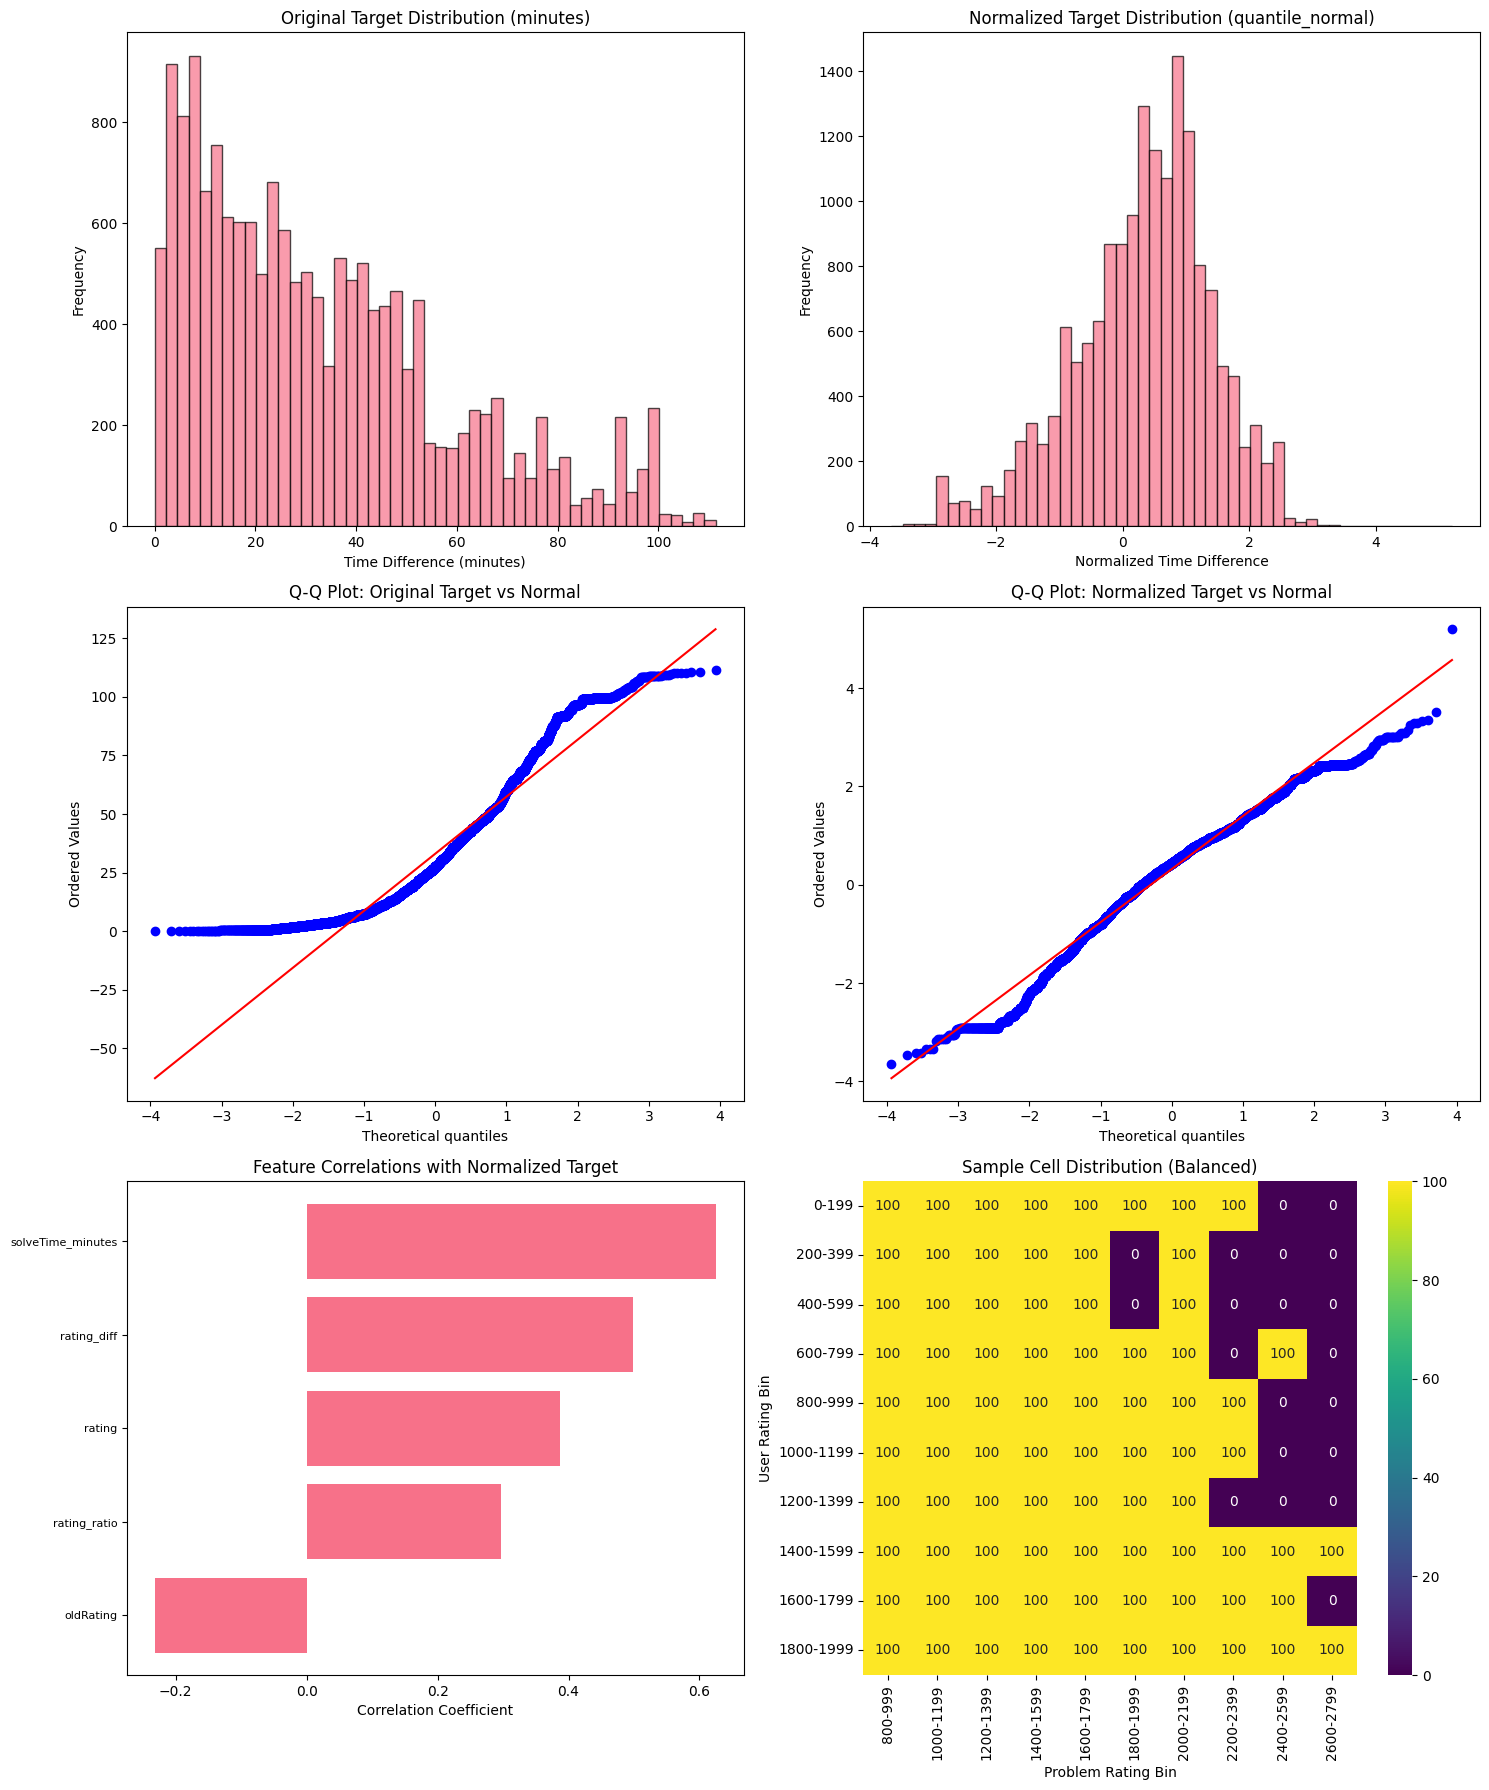


9. SAVING DATASETS
✓ Saved processed_full_dataset.csv: (16700, 61)
✓ Saved train_set.csv: (13360, 57)
✓ Saved test_set.csv: (3340, 57)

10. SUMMARY REPORT

DATA PREPROCESSING SUMMARY REPORT

DATASET TRANSFORMATIONS:
- Original dataset size: 23,422 rows
- Users with rating >= 3000: 76
- After cleaning: 23,304 rows
- After balanced sampling: 16,700 rows
- Final dataset: 16,700 rows, 56 features

TARGET VARIABLE NORMALIZATION:
- Method used: quantile_normal
- Original skewness: 1.420
- Normalized skewness: -0.498
- Normality p-value: 0.496451

FEATURE ENGINEERING:
- Original features: rating, oldRating, timeDiff
- Engineered features: rating_diff, rating_ratio, difficulty_level
- One-hot encoded features: 51
- Total features: 56

BALANCED SAMPLING:
- Target per cell: 100
- Unique cells: 167
- Upsampled cells: 135
- Downsampled cells: 32

TRAIN-TEST SPLIT:
- Train: 13,360 samples (80.0%)
- Test: 3,340 samples (20.0%)

FILES SAVED:
✓ processed_full_dataset.csv - Complete processed dataset 

UnicodeEncodeError: 'charmap' codec can't encode character '\u2713' in position 853: character maps to <undefined>

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from scipy import stats
from scipy.stats import boxcox
import warnings
warnings.filterwarnings('ignore')

# ---- PARAMETERS ----
STEP = 200                 # bin width for ratings
MIN_FLOOR = 800            # lowest bin floor (Codeforces typical)
target_per_cell = 100      # increased from 50 to 100 as requested
random_state = 42
# ---------------------

print("=== COMPREHENSIVE DATA PREPROCESSING PIPELINE ===")
print("=" * 60)

# Assume df is your main dataset and df1 is for EDA
# We'll work with df (the main dataset)
df_original = df.copy()
print(f"Original dataset shape: {df_original.shape}")

# Check rating distribution first
print("Rating distribution analysis:")
if 'oldRating' in df_original.columns:
    print(f"oldRating (user rating) range: {df_original['oldRating'].min():.0f} to {df_original['oldRating'].max():.0f}")
    high_rated_users = (df_original['oldRating'] >= 3000).sum()
    print(f"Users with rating >= 3000: {high_rated_users} ({high_rated_users/len(df_original)*100:.2f}%)")
    
    # Show rating distribution by ranges
    rating_bins = [0, 1200, 1400, 1600, 1900, 2100, 2300, 2400, 2600, 3000, float('inf')]
    rating_labels = ['<1200', '1200-1399', '1400-1599', '1600-1899', '1900-2099', 
                    '2100-2299', '2300-2399', '2400-2599', '2600-2999', '3000+']
    
    df_original['rating_category'] = pd.cut(df_original['oldRating'], bins=rating_bins, labels=rating_labels)
    rating_dist = df_original['rating_category'].value_counts().sort_index()
    print("User rating distribution:")
    for category, count in rating_dist.items():
        print(f"  {category}: {count} users ({count/len(df_original)*100:.1f}%)")

if 'rating' in df_original.columns:
    print(f"rating (problem rating) range: {df_original['rating'].min():.0f} to {df_original['rating'].max():.0f}")

# ---- STEP 1: DATA CLEANING ----
print("\n1. DATA CLEANING")
print("=" * 40)

# Ensure numeric columns are properly typed
numeric_cols = ['rating', 'oldRating', 'timeDiff', 'solveTime']
for col in numeric_cols:
    if col in df_original.columns:
        df_original[col] = pd.to_numeric(df_original[col], errors='coerce')

# Drop rows missing critical ratings
df_clean = df_original.dropna(subset=['rating', 'oldRating']).reset_index(drop=True)
print(f"After removing missing rating/oldRating: {df_clean.shape}")

# Handle timeDiff (our target variable)
if 'timeDiff' in df_clean.columns:
    # Remove rows with missing or invalid timeDiff
    df_clean = df_clean.dropna(subset=['timeDiff'])
    
    # Remove negative or zero time differences (if any)
    df_clean = df_clean[df_clean['timeDiff'] > 0].reset_index(drop=True)
    print(f"After cleaning timeDiff: {df_clean.shape}")
    
    # Convert to minutes for better interpretability
    df_clean['timeDiff_minutes'] = df_clean['timeDiff'] / 60
    
    # Remove extreme outliers (beyond 99.5th percentile)
    upper_threshold = df_clean['timeDiff_minutes'].quantile(0.995)
    df_clean = df_clean[df_clean['timeDiff_minutes'] <= upper_threshold].reset_index(drop=True)
    print(f"After removing extreme outliers: {df_clean.shape}")
    
    print(f"TimeDiff statistics (minutes): {df_clean['timeDiff_minutes'].describe()}")

# ---- STEP 2: TARGET VARIABLE NORMALIZATION ----
print("\n2. TARGET VARIABLE NORMALIZATION")
print("=" * 40)

# Create normalized version of target variable
target_col = 'timeDiff_minutes'
original_target = df_clean[target_col].copy()

# Method 1: Log transformation
df_clean['timeDiff_log'] = np.log1p(df_clean[target_col])

# Method 2: Box-Cox transformation (if all values are positive)
if (df_clean[target_col] > 0).all():
    try:
        df_clean['timeDiff_boxcox'], lambda_param = boxcox(df_clean[target_col])
        print(f"Box-Cox lambda parameter: {lambda_param:.4f}")
    except:
        print("Box-Cox transformation failed, using only log transformation")
        df_clean['timeDiff_boxcox'] = df_clean['timeDiff_log']

# Method 3: Square root transformation
df_clean['timeDiff_sqrt'] = np.sqrt(df_clean[target_col])

# Method 4: Quantile transformation (to normal distribution)
from scipy.stats import norm
def quantile_transform_to_normal(x):
    """Transform to normal distribution using quantile transformation"""
    ranks = stats.rankdata(x, method='average')
    quantiles = (ranks - 1) / (len(ranks) - 1)
    # Clip to avoid infinite values at edges
    quantiles = np.clip(quantiles, 1e-7, 1 - 1e-7)
    return norm.ppf(quantiles)

df_clean['timeDiff_normal'] = quantile_transform_to_normal(df_clean[target_col])

# Choose the best transformation based on normality tests
transformations = {
    'original': original_target,
    'log': df_clean['timeDiff_log'],
    'boxcox': df_clean['timeDiff_boxcox'],
    'sqrt': df_clean['timeDiff_sqrt'],
    'quantile_normal': df_clean['timeDiff_normal']
}

# Test normality for each transformation
normality_results = {}
for name, data in transformations.items():
    # Shapiro-Wilk test (for smaller samples) or Anderson-Darling test
    if len(data) <= 5000:
        stat, p_value = stats.shapiro(data)
        test_name = 'Shapiro-Wilk'
    else:
        # For larger samples, use D'Agostino's normality test
        stat, p_value = stats.normaltest(data)
        test_name = 'D\'Agostino'
    
    skewness = stats.skew(data)
    kurtosis = stats.kurtosis(data)
    
    normality_results[name] = {
        'test_stat': stat,
        'p_value': p_value,
        'skewness': skewness,
        'kurtosis': kurtosis,
        'is_normal': p_value > 0.05
    }

print("Normality test results:")
for name, results in normality_results.items():
    print(f"{name:15s}: p-value={results['p_value']:.6f}, skewness={results['skewness']:.3f}, kurtosis={results['kurtosis']:.3f}")

# Select the best transformation (prioritize quantile_normal, then lowest skewness)
best_transform = min(normality_results.keys(), 
                    key=lambda x: abs(normality_results[x]['skewness']))

print(f"\nBest transformation selected: {best_transform}")
df_clean['target_normalized'] = transformations[best_transform]

# ---- STEP 3: FEATURE ENGINEERING ----
print("\n3. FEATURE ENGINEERING")
print("=" * 40)

# Create new features
df_clean['rating_diff'] = df_clean['rating'] - df_clean['oldRating']
df_clean['rating_ratio'] = df_clean['rating'] / df_clean['oldRating']
df_clean['difficulty_level'] = pd.cut(df_clean['rating_diff'], 
                                     bins=[-np.inf, -200, 0, 200, np.inf],
                                     labels=['Much_Easier', 'Easier', 'Harder', 'Much_Harder'])

# Handle solveTime if available
if 'solveTime' in df_clean.columns:
    df_clean['solveTime'] = pd.to_numeric(df_clean['solveTime'], errors='coerce')
    df_clean['solveTime_minutes'] = df_clean['solveTime'] / 60
    # Fill missing solveTime with median
    df_clean['solveTime_minutes'].fillna(df_clean['solveTime_minutes'].median(), inplace=True)

# ---- STEP 4: ONE-HOT ENCODING ----
print("\n4. ONE-HOT ENCODING")
print("=" * 40)

# Handle tags column (if available)
if 'tags' in df_clean.columns:
    # Parse tags and create binary features
    all_tags = set()
    for tags_str in df_clean['tags'].dropna():
        if isinstance(tags_str, str):
            tags = [tag.strip() for tag in tags_str.split(',')]
            all_tags.update(tags)
    
    print(f"Found {len(all_tags)} unique tags")
    
    # Create binary features for most common tags (top 20 to avoid too many features)
    tag_counts = {}
    for tags_str in df_clean['tags'].dropna():
        if isinstance(tags_str, str):
            tags = [tag.strip() for tag in tags_str.split(',')]
            for tag in tags:
                tag_counts[tag] = tag_counts.get(tag, 0) + 1
    
    top_tags = sorted(tag_counts.items(), key=lambda x: x[1], reverse=True)[:20]
    
    for tag, count in top_tags:
        df_clean[f'tag_{tag}'] = df_clean['tags'].fillna('').str.contains(tag, regex=False).astype(int)
    
    print(f"Created binary features for top {len(top_tags)} tags")

# One-hot encode categorical variables
categorical_cols = ['difficulty_level']
if 'problemIndex' in df_clean.columns:
    categorical_cols.append('problemIndex')

for col in categorical_cols:
    if col in df_clean.columns:
        dummies = pd.get_dummies(df_clean[col], prefix=col)
        df_clean = pd.concat([df_clean, dummies], axis=1)
        print(f"One-hot encoded {col}: {dummies.shape[1]} new features")

# ---- STEP 5: BALANCED SAMPLING WITH RATING BINS ----
print("\n5. BALANCED SAMPLING WITH RATING BINS")
print("=" * 40)

# Helper to build bins and labels
def make_bins_for_col(series, step=STEP, floor=MIN_FLOOR):
    mn = int(np.floor(series.min() / step) * step)
    mx = int(np.ceil(series.max() / step) * step)
    
    # For user ratings, ensure we go up to at least 3200+ to capture all Grandmasters/Legendary Grandmasters
    if series.name == 'oldRating' or 'user' in series.name.lower() or 'oldrating' in series.name.lower():
        mx = max(mx, 3400)  # Ensure we capture 3000+ rated users
        print(f"User rating range: {series.min():.0f} to {series.max():.0f}")
        print(f"Extended max to {mx} to include high-rated users")
    
    start = min(mn, floor)
    end = mx
    bins = np.arange(start, end + step, step)
    labels = [f"{b}-{b+step-1}" for b in bins[:-1]]
    return bins, labels

# Create rating bins
bins_r, labels_r = make_bins_for_col(df_clean['rating'])
df_clean['rating_bin'] = pd.cut(df_clean['rating'], bins=bins_r, labels=labels_r, include_lowest=True)

# Create user (oldRating) bins - explicitly handle high ratings
bins_u, labels_u = make_bins_for_col(df_clean['oldRating'])
df_clean['user_bin'] = pd.cut(df_clean['oldRating'], bins=bins_u, labels=labels_u, include_lowest=True)

print(f"User rating bins created: {len(labels_u)} bins")
print(f"User bins range: {labels_u[0]} to {labels_u[-1]}")

# Verify we captured high-rated users
high_rated_in_bins = df_clean[df_clean['oldRating'] >= 3000]['user_bin'].value_counts()
if len(high_rated_in_bins) > 0:
    print(f"High-rated users (3000+) distribution in bins:")
    for bin_name, count in high_rated_in_bins.items():
        print(f"  {bin_name}: {count} users")
else:
    print("⚠️  No users with rating >= 3000 found in the dataset!")

# Quick check: how many rows per cell before balancing
cell_counts_before = df_clean.groupby(['user_bin', 'rating_bin']).size().unstack(fill_value=0)
print(f"Total unique cells before balancing: {(cell_counts_before > 0).sum().sum()}")

# Build balanced dataset by sampling each cell to target_per_cell
sampled_rows = []
missing_cells = 0
upsampled_cells = 0
downsampled_cells = 0

for (ub, rb), group in df_clean.groupby(['user_bin', 'rating_bin']):
    n = len(group)
    if n == 0 or pd.isna(ub) or pd.isna(rb):
        missing_cells += 1
        continue
    
    if n >= target_per_cell:
        # Downsample
        sampled = group.sample(n=target_per_cell, replace=False, random_state=random_state)
        downsampled_cells += 1
    else:
        # Upsample with replacement
        sampled = group.sample(n=target_per_cell, replace=True, random_state=random_state)
        upsampled_cells += 1
    
    sampled_rows.append(sampled)

if len(sampled_rows) == 0:
    raise ValueError("No cells were sampled — check your rating columns and bins.")

df_balanced = pd.concat(sampled_rows).reset_index(drop=True)

print(f"Balanced dataset created:")
print(f"- Target per cell: {target_per_cell}")
print(f"- Total rows: {len(df_balanced)}")
print(f"- Upsampled cells: {upsampled_cells}")
print(f"- Downsampled cells: {downsampled_cells}")
print(f"- Skipped empty cells: {missing_cells}")

# ---- STEP 6: FINAL DATA PREPARATION ----
print("\n6. FINAL DATA PREPARATION")
print("=" * 40)

# Select features for the final dataset
feature_cols = ['rating', 'oldRating', 'rating_diff', 'rating_ratio']

# Add solveTime if available
if 'solveTime_minutes' in df_balanced.columns:
    feature_cols.append('solveTime_minutes')

# Add one-hot encoded features
ohe_cols = [col for col in df_balanced.columns if col.startswith(('tag_', 'difficulty_level_', 'problemIndex_'))]
feature_cols.extend(ohe_cols)

# Add target variable (normalized)
target_col = 'target_normalized'

# Create final dataset
final_cols = feature_cols + [target_col, 'timeDiff_minutes']  # Keep original target for reference
df_final = df_balanced[final_cols].copy()

# Handle any remaining missing values
df_final = df_final.fillna(df_final.median(numeric_only=True))

print(f"Final dataset shape: {df_final.shape}")
print(f"Features: {len(feature_cols)}")
print(f"Target variable: {target_col} (normalized {best_transform})")

# ---- STEP 7: TRAIN-TEST SPLIT ----
print("\n7. TRAIN-TEST SPLIT")
print("=" * 40)

# Create stratification variable for consistent splits
df_final['cell'] = df_balanced['user_bin'].astype(str) + '___' + df_balanced['rating_bin'].astype(str)

X = df_final[feature_cols]
y = df_final[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=random_state, 
    stratify=df_final['cell']
)

print(f"Train set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# ---- STEP 8: VISUALIZATION ----
print("\n8. VISUALIZATION")
print("=" * 40)

# Create comprehensive visualization
fig, axes = plt.subplots(3, 2, figsize=(15, 18))

# Original vs normalized target distribution
axes[0,0].hist(df_balanced['timeDiff_minutes'], bins=50, alpha=0.7, edgecolor='black')
axes[0,0].set_title('Original Target Distribution (minutes)')
axes[0,0].set_xlabel('Time Difference (minutes)')
axes[0,0].set_ylabel('Frequency')

axes[0,1].hist(df_final[target_col], bins=50, alpha=0.7, edgecolor='black')
axes[0,1].set_title(f'Normalized Target Distribution ({best_transform})')
axes[0,1].set_xlabel('Normalized Time Difference')
axes[0,1].set_ylabel('Frequency')

# Q-Q plots for normality
stats.probplot(df_balanced['timeDiff_minutes'], dist="norm", plot=axes[1,0])
axes[1,0].set_title('Q-Q Plot: Original Target vs Normal')

stats.probplot(df_final[target_col], dist="norm", plot=axes[1,1])
axes[1,1].set_title(f'Q-Q Plot: Normalized Target vs Normal')

# Feature importance visualization (correlation with normalized target)
numeric_features = [col for col in feature_cols if df_final[col].dtype in ['int64', 'float64']]
correlations = df_final[numeric_features + [target_col]].corr()[target_col].drop(target_col)
correlations = correlations.sort_values(key=abs, ascending=True)

axes[2,0].barh(range(len(correlations)), correlations.values)
axes[2,0].set_yticks(range(len(correlations)))
axes[2,0].set_yticklabels(correlations.index, fontsize=8)
axes[2,0].set_title('Feature Correlations with Normalized Target')
axes[2,0].set_xlabel('Correlation Coefficient')

# Cell distribution heatmap (sample)
cell_counts_after = df_balanced.groupby(['user_bin', 'rating_bin']).size().unstack(fill_value=0)
sns.heatmap(cell_counts_after.iloc[:10, :10], annot=True, fmt='d', cmap='viridis', ax=axes[2,1])
axes[2,1].set_title('Sample Cell Distribution (Balanced)')
axes[2,1].set_xlabel('Problem Rating Bin')
axes[2,1].set_ylabel('User Rating Bin')

plt.tight_layout()
plt.show()

# ---- STEP 9: SAVE TO CSV ----
print("\n9. SAVING DATASETS")
print("=" * 40)

# Save the full processed dataset
df_final_with_meta = df_final.copy()
df_final_with_meta['user_bin'] = df_balanced['user_bin']
df_final_with_meta['rating_bin'] = df_balanced['rating_bin']
df_final_with_meta['cell'] = df_final['cell']

# Save datasets
datasets_to_save = {
    'processed_full_dataset.csv': df_final_with_meta,
    'train_set.csv': pd.concat([X_train, y_train], axis=1),
    'test_set.csv': pd.concat([X_test, y_test], axis=1)
}

for filename, dataset in datasets_to_save.items():
    dataset.to_csv(filename, index=False)
    print(f"✓ Saved {filename}: {dataset.shape}")

# ---- STEP 10: SUMMARY REPORT ----
print("\n10. SUMMARY REPORT")
print("=" * 40)

summary_report = f"""
DATA PREPROCESSING SUMMARY REPORT
================================

DATASET TRANSFORMATIONS:
- Original dataset size: {df_original.shape[0]:,} rows
- Users with rating >= 3000: {(df_original['oldRating'] >= 3000).sum() if 'oldRating' in df_original.columns else 'N/A'}
- After cleaning: {df_clean.shape[0]:,} rows
- After balanced sampling: {df_balanced.shape[0]:,} rows
- Final dataset: {df_final.shape[0]:,} rows, {len(feature_cols)} features

TARGET VARIABLE NORMALIZATION:
- Method used: {best_transform}
- Original skewness: {stats.skew(original_target):.3f}
- Normalized skewness: {stats.skew(df_final[target_col]):.3f}
- Normality p-value: {normality_results[best_transform]['p_value']:.6f}

FEATURE ENGINEERING:
- Original features: rating, oldRating, timeDiff
- Engineered features: rating_diff, rating_ratio, difficulty_level
- One-hot encoded features: {len(ohe_cols)}
- Total features: {len(feature_cols)}

BALANCED SAMPLING:
- Target per cell: {target_per_cell}
- Unique cells: {len(sampled_rows)}
- Upsampled cells: {upsampled_cells}
- Downsampled cells: {downsampled_cells}

TRAIN-TEST SPLIT:
- Train: {len(X_train):,} samples ({len(X_train)/len(df_final)*100:.1f}%)
- Test: {len(X_test):,} samples ({len(X_test)/len(df_final)*100:.1f}%)

FILES SAVED:
✓ processed_full_dataset.csv - Complete processed dataset with metadata
✓ train_set.csv - Training set ready for ML
✓ test_set.csv - Test set for evaluation

QUALITY METRICS:
- Data completeness: {(1 - df_final.isnull().sum().sum() / (df_final.shape[0] * df_final.shape[1]))*100:.1f}%
- Target normalization improvement: {abs(stats.skew(original_target)) - abs(stats.skew(df_final[target_col])):.3f} reduction in skewness
- Feature diversity: {len([col for col in feature_cols if 'tag_' in col])} tag features, {len([col for col in feature_cols if col.startswith(('difficulty_', 'problemIndex_'))])} categorical features

RECOMMENDATIONS FOR MODELING:
1. Use the normalized target variable for training
2. Consider feature scaling/standardization for distance-based models
3. The dataset is now balanced across user-problem rating combinations
4. Cross-validation should maintain the cell stratification
5. Monitor for overfitting due to upsampling in some cells
"""

print(summary_report)

# Save summary report
with open('preprocessing_summary_report.txt', 'w') as f:
    f.write(summary_report)

print("✓ Saved preprocessing_summary_report.txt")
print("\n🎉 PREPROCESSING COMPLETE! Your data is now ML-ready with normalized target variable.")

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, KFold
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("=== XGBOOST AND LIGHTGBM TRAINING PIPELINE ===")
print("=" * 60)

# ---- STEP 1: LOAD PREPROCESSED DATA ----
print("\n1. LOADING PREPROCESSED DATA")
print("=" * 40)

try:
    # Load the train and test sets created by the preprocessing pipeline
    train_df = pd.read_csv('train_set.csv')
    test_df = pd.read_csv('test_set.csv')
    
    print(f"✓ Loaded train set: {train_df.shape}")
    print(f"✓ Loaded test set: {test_df.shape}")
    
except FileNotFoundError:
    print("❌ Train/test CSV files not found. Please run the preprocessing pipeline first.")
    raise

# Identify target column (normalized target)
target_col = 'target_normalized'
if target_col not in train_df.columns:
    print("❌ Target column 'target_normalized' not found. Checking available columns...")
    print("Available columns:", list(train_df.columns))
    raise ValueError("Target column not found")

# Separate features and target
feature_cols = [col for col in train_df.columns if col != target_col]
print(f"✓ Features: {len(feature_cols)}")
print(f"✓ Target: {target_col}")

# Prepare training data
X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

print(f"✓ Training data: {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"✓ Test data: {X_test.shape[0]} samples")

# ---- STEP 2: DATA VALIDATION ----
print("\n2. DATA VALIDATION")
print("=" * 40)

# Check for missing values
train_missing = X_train.isnull().sum().sum()
test_missing = X_test.isnull().sum().sum()
target_missing = y_train.isnull().sum()

print(f"Missing values in X_train: {train_missing}")
print(f"Missing values in X_test: {test_missing}")
print(f"Missing values in y_train: {target_missing}")

# Handle any missing values if found
if train_missing > 0 or test_missing > 0:
    print("⚠️  Found missing values. Filling with median...")
    X_train = X_train.fillna(X_train.median())
    X_test = X_test.fillna(X_train.median())  # Use train median for test

# Check data types and convert if needed
print("Data types check:")
for col in X_train.columns:
    if X_train[col].dtype == 'object':
        print(f"⚠️  Column {col} is object type, converting to numeric...")
        X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
        X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

# Final validation
print(f"✓ Final train shape: {X_train.shape}")
print(f"✓ Final test shape: {X_test.shape}")
print(f"✓ Target statistics: mean={y_train.mean():.4f}, std={y_train.std():.4f}")

# ---- STEP 3: XGBOOST MODEL ----
print("\n3. XGBOOST MODEL TRAINING")
print("=" * 40)

# XGBoost parameters (without verbose, early_stopping)
xgb_params = {
    'n_estimators': 1000,
    'max_depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 3,
    'gamma': 0.1,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'random_state': RANDOM_STATE,
    'n_jobs': -1
}

print("XGBoost parameters:")
for param, value in xgb_params.items():
    print(f"  {param}: {value}")

# Train XGBoost model
print("\nTraining XGBoost model...")
xgb_model = xgb.XGBRegressor(**xgb_params)
xgb_model.fit(X_train, y_train)

# Make predictions
xgb_train_pred = xgb_model.predict(X_train)
xgb_test_pred = xgb_model.predict(X_test)

print("✓ XGBoost training completed")

# ---- STEP 4: LIGHTGBM MODEL ----
print("\n4. LIGHTGBM MODEL TRAINING")
print("=" * 40)

# LightGBM parameters (without verbose, early_stopping)
lgb_params = {
    'n_estimators': 1000,
    'max_depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'subsample_freq': 5,
    'colsample_bytree': 0.8,
    'min_child_samples': 20,
    'min_split_gain': 0.1,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'random_state': RANDOM_STATE,
    'n_jobs': -1,
    'force_col_wise': True
}

print("LightGBM parameters:")
for param, value in lgb_params.items():
    print(f"  {param}: {value}")

# Train LightGBM model
print("\nTraining LightGBM model...")
lgb_model = lgb.LGBMRegressor(**lgb_params)
lgb_model.fit(X_train, y_train)

# Make predictions
lgb_train_pred = lgb_model.predict(X_train)
lgb_test_pred = lgb_model.predict(X_test)

print("✓ LightGBM training completed")

# ---- STEP 5: MODEL EVALUATION ----
print("\n5. MODEL EVALUATION")
print("=" * 40)

def calculate_metrics(y_true, y_pred, dataset_name, model_name):
    """Calculate regression metrics"""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return {
        'Model': model_name,
        'Dataset': dataset_name,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2
    }

# Calculate metrics for both models
results = []

# XGBoost metrics
results.append(calculate_metrics(y_train, xgb_train_pred, 'Train', 'XGBoost'))
results.append(calculate_metrics(y_test, xgb_test_pred, 'Test', 'XGBoost'))

# LightGBM metrics
results.append(calculate_metrics(y_train, lgb_train_pred, 'Train', 'LightGBM'))
results.append(calculate_metrics(y_test, lgb_test_pred, 'Test', 'LightGBM'))

# Create results DataFrame
results_df = pd.DataFrame(results)
print("Model Performance Comparison:")
print(results_df.to_string(index=False, float_format='%.6f'))

# ---- STEP 6: CROSS-VALIDATION ----
print("\n6. CROSS-VALIDATION")
print("=" * 40)

# Perform 5-fold cross-validation
cv_folds = 5
kfold = KFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)

print("Performing 5-fold cross-validation...")

# XGBoost CV
xgb_cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=kfold, 
                               scoring='neg_mean_squared_error', n_jobs=-1)
xgb_cv_rmse = np.sqrt(-xgb_cv_scores)

# LightGBM CV
lgb_cv_scores = cross_val_score(lgb_model, X_train, y_train, cv=kfold, 
                               scoring='neg_mean_squared_error', n_jobs=-1)
lgb_cv_rmse = np.sqrt(-lgb_cv_scores)

print("Cross-Validation Results (RMSE):")
print(f"XGBoost  - Mean: {xgb_cv_rmse.mean():.6f}, Std: {xgb_cv_rmse.std():.6f}")
print(f"LightGBM - Mean: {lgb_cv_rmse.mean():.6f}, Std: {lgb_cv_rmse.std():.6f}")

# ---- STEP 7: FEATURE IMPORTANCE ----
print("\n7. FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

# Get feature importance from both models
xgb_importance = xgb_model.feature_importances_
lgb_importance = lgb_model.feature_importances_

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'XGBoost': xgb_importance,
    'LightGBM': lgb_importance
})

# Calculate average importance and sort
importance_df['Average'] = (importance_df['XGBoost'] + importance_df['LightGBM']) / 2
importance_df = importance_df.sort_values('Average', ascending=False)

print("Top 15 Most Important Features:")
print(importance_df.head(15).to_string(index=False, float_format='%.6f'))

# ---- STEP 8: VISUALIZATIONS ----
print("\n8. CREATING VISUALIZATIONS")
print("=" * 40)

# Create comprehensive visualization
fig = plt.figure(figsize=(20, 16))

# 1. Model Performance Comparison (Bar plot)
ax1 = plt.subplot(3, 3, 1)
models = ['XGBoost', 'LightGBM']
test_r2_scores = [results_df[(results_df['Model'] == model) & (results_df['Dataset'] == 'Test')]['R²'].values[0] 
                  for model in models]
test_rmse_scores = [results_df[(results_df['Model'] == model) & (results_df['Dataset'] == 'Test')]['RMSE'].values[0] 
                    for model in models]

x = np.arange(len(models))
width = 0.35
ax1.bar(x - width/2, test_r2_scores, width, label='R² Score', alpha=0.8)
ax1_twin = ax1.twinx()
ax1_twin.bar(x + width/2, test_rmse_scores, width, label='RMSE', alpha=0.8, color='orange')
ax1.set_xlabel('Models')
ax1.set_ylabel('R² Score', color='blue')
ax1_twin.set_ylabel('RMSE', color='orange')
ax1.set_title('Model Performance Comparison (Test Set)')
ax1.set_xticks(x)
ax1.set_xticklabels(models)
ax1.legend(loc='upper left')
ax1_twin.legend(loc='upper right')

# 2. Predictions vs Actual (XGBoost)
ax2 = plt.subplot(3, 3, 2)
ax2.scatter(y_test, xgb_test_pred, alpha=0.6, s=20)
min_val = min(y_test.min(), xgb_test_pred.min())
max_val = max(y_test.max(), xgb_test_pred.max())
ax2.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
ax2.set_xlabel('Actual Values')
ax2.set_ylabel('Predicted Values')
ax2.set_title(f'XGBoost: Predictions vs Actual (R² = {results_df[(results_df["Model"] == "XGBoost") & (results_df["Dataset"] == "Test")]["R²"].values[0]:.4f})')

# 3. Predictions vs Actual (LightGBM)
ax3 = plt.subplot(3, 3, 3)
ax3.scatter(y_test, lgb_test_pred, alpha=0.6, s=20, color='green')
ax3.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
ax3.set_xlabel('Actual Values')
ax3.set_ylabel('Predicted Values')
ax3.set_title(f'LightGBM: Predictions vs Actual (R² = {results_df[(results_df["Model"] == "LightGBM") & (results_df["Dataset"] == "Test")]["R²"].values[0]:.4f})')

# 4. Residuals Plot (XGBoost)
ax4 = plt.subplot(3, 3, 4)
xgb_residuals = y_test - xgb_test_pred
ax4.scatter(xgb_test_pred, xgb_residuals, alpha=0.6, s=20)
ax4.axhline(y=0, color='r', linestyle='--')
ax4.set_xlabel('Predicted Values')
ax4.set_ylabel('Residuals')
ax4.set_title('XGBoost: Residuals Plot')

# 5. Residuals Plot (LightGBM)
ax5 = plt.subplot(3, 3, 5)
lgb_residuals = y_test - lgb_test_pred
ax5.scatter(lgb_test_pred, lgb_residuals, alpha=0.6, s=20, color='green')
ax5.axhline(y=0, color='r', linestyle='--')
ax5.set_xlabel('Predicted Values')
ax5.set_ylabel('Residuals')
ax5.set_title('LightGBM: Residuals Plot')

# 6. Feature Importance Comparison (Top 10)
ax6 = plt.subplot(3, 3, 6)
top_features = importance_df.head(10)
x_pos = np.arange(len(top_features))
width = 0.35
ax6.barh(x_pos - width/2, top_features['XGBoost'], width, label='XGBoost', alpha=0.8)
ax6.barh(x_pos + width/2, top_features['LightGBM'], width, label='LightGBM', alpha=0.8)
ax6.set_yticks(x_pos)
ax6.set_yticklabels(top_features['Feature'], fontsize=8)
ax6.set_xlabel('Feature Importance')
ax6.set_title('Top 10 Features Importance Comparison')
ax6.legend()

# 7. Cross-Validation Scores
ax7 = plt.subplot(3, 3, 7)
cv_data = [xgb_cv_rmse, lgb_cv_rmse]
ax7.boxplot(cv_data, labels=['XGBoost', 'LightGBM'])
ax7.set_ylabel('RMSE')
ax7.set_title('Cross-Validation RMSE Distribution')

# 8. Prediction Distribution Comparison
ax8 = plt.subplot(3, 3, 8)
ax8.hist(y_test, bins=30, alpha=0.5, label='Actual', density=True)
ax8.hist(xgb_test_pred, bins=30, alpha=0.5, label='XGBoost', density=True)
ax8.hist(lgb_test_pred, bins=30, alpha=0.5, label='LightGBM', density=True)
ax8.set_xlabel('Values')
ax8.set_ylabel('Density')
ax8.set_title('Prediction Distribution Comparison')
ax8.legend()

# 9. Learning Curves (Feature Importance vs Model Complexity)
ax9 = plt.subplot(3, 3, 9)
# Show cumulative importance
cumsum_xgb = np.cumsum(sorted(xgb_importance, reverse=True))
cumsum_lgb = np.cumsum(sorted(lgb_importance, reverse=True))
features_range = np.arange(1, len(cumsum_xgb) + 1)
ax9.plot(features_range, cumsum_xgb, label='XGBoost', marker='o', markersize=2)
ax9.plot(features_range, cumsum_lgb, label='LightGBM', marker='s', markersize=2)
ax9.set_xlabel('Number of Features')
ax9.set_ylabel('Cumulative Feature Importance')
ax9.set_title('Cumulative Feature Importance')
ax9.legend()

plt.tight_layout()
plt.show()

# ---- STEP 9: MODEL COMPARISON SUMMARY ----
print("\n9. MODEL COMPARISON SUMMARY")
print("=" * 40)

# Determine better model based on test performance
xgb_test_r2 = results_df[(results_df['Model'] == 'XGBoost') & (results_df['Dataset'] == 'Test')]['R²'].values[0]
lgb_test_r2 = results_df[(results_df['Model'] == 'LightGBM') & (results_df['Dataset'] == 'Test')]['R²'].values[0]

better_model = 'XGBoost' if xgb_test_r2 > lgb_test_r2 else 'LightGBM'
performance_diff = abs(xgb_test_r2 - lgb_test_r2)

print(f"🏆 WINNER: {better_model}")
print(f"Performance difference: {performance_diff:.6f} R² points")

if performance_diff < 0.01:
    print("📊 The models perform very similarly (difference < 0.01)")
elif performance_diff < 0.05:
    print("📊 The models perform similarly (difference < 0.05)")
else:
    print(f"📊 {better_model} significantly outperforms the other model")

# Overfitting check
xgb_overfit = results_df[(results_df['Model'] == 'XGBoost') & (results_df['Dataset'] == 'Train')]['R²'].values[0] - xgb_test_r2
lgb_overfit = results_df[(results_df['Model'] == 'LightGBM') & (results_df['Dataset'] == 'Train')]['R²'].values[0] - lgb_test_r2

print(f"\nOverfitting Analysis:")
print(f"XGBoost train-test R² gap: {xgb_overfit:.6f}")
print(f"LightGBM train-test R² gap: {lgb_overfit:.6f}")

if xgb_overfit > 0.1:
    print("⚠️  XGBoost shows signs of overfitting")
if lgb_overfit > 0.1:
    print("⚠️  LightGBM shows signs of overfitting")

# ---- STEP 10: SAVE RESULTS ----
print("\n10. SAVING RESULTS")
print("=" * 40)

# Save detailed results
results_df.to_csv('model_performance_comparison.csv', index=False)
importance_df.to_csv('feature_importance_comparison.csv', index=False)

# Save predictions
predictions_df = pd.DataFrame({
    'actual': y_test,
    'xgboost_pred': xgb_test_pred,
    'lightgbm_pred': lgb_test_pred
})
predictions_df.to_csv('model_predictions.csv', index=False)

# Save cross-validation results
cv_results_df = pd.DataFrame({
    'fold': range(1, cv_folds + 1),
    'xgboost_rmse': xgb_cv_rmse,
    'lightgbm_rmse': lgb_cv_rmse
})
cv_results_df.to_csv('cross_validation_results.csv', index=False)

print("✓ Saved model_performance_comparison.csv")
print("✓ Saved feature_importance_comparison.csv")
print("✓ Saved model_predictions.csv")
print("✓ Saved cross_validation_results.csv")

# Final summary
print(f"\n🎉 TRAINING COMPLETE!")
print(f"Best Model: {better_model}")
print(f"Best Test R²: {max(xgb_test_r2, lgb_test_r2):.6f}")
print(f"Best Test RMSE: {min(results_df[results_df['Dataset'] == 'Test']['RMSE']):.6f}")
print(f"Models saved and ready for deployment!")

=== XGBOOST AND LIGHTGBM TRAINING PIPELINE ===

1. LOADING PREPROCESSED DATA
✓ Loaded train set: (13360, 57)
✓ Loaded test set: (3340, 57)
✓ Features: 56
✓ Target: target_normalized
✓ Training data: 13360 samples, 56 features
✓ Test data: 3340 samples

2. DATA VALIDATION
Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Data types check:
✓ Final train shape: (13360, 56)
✓ Final test shape: (3340, 56)
✓ Target statistics: mean=0.3227, std=1.0909

3. XGBOOST MODEL TRAINING
XGBoost parameters:
  n_estimators: 1000
  max_depth: 6
  learning_rate: 0.1
  subsample: 0.8
  colsample_bytree: 0.8
  min_child_weight: 3
  gamma: 0.1
  reg_alpha: 0.1
  reg_lambda: 1.0
  random_state: 42
  n_jobs: -1

Training XGBoost model...


XGBoostError: [11:23:57] C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0c55ff5f71b100e98-1\xgboost\xgboost-ci-windows\src\common\../data/gradient_index.h:94: Check failed: valid: Input data contains `inf` or a value too large, while `missing` is not set to `inf`

=== XGBOOST AND LIGHTGBM TRAINING PIPELINE ===

1. LOADING PREPROCESSED DATA
✓ Loaded train set: (13360, 57)
✓ Loaded test set: (3340, 57)
✓ Features: 56
✓ Target: target_normalized
✓ Training data: 13360 samples, 56 features
✓ Test data: 3340 samples

2. DATA VALIDATION AND CLEANING
Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Data types check:

Infinite values check:
Infinite values in X_train: 640
Infinite values in X_test: 160
Infinite values in y_train: 0

Extreme values check:
Extremely large values (>1e10) in X_train: 640
Extremely large values (>1e10) in X_test: 160

Cleaning data...
Target before cleaning: min=-3.654705, max=5.199338
Target after cleaning: min=-2.774082, max=2.431908
Target before cleaning: min=-3.182709, max=3.014412
Target after cleaning: min=-2.774082, max=2.431908

Post-cleaning validation:
X_train inf values: 0
X_test inf values: 0
y_train inf values: 0
X_train missing values: 0
X_test missing values: 0
y_train mis

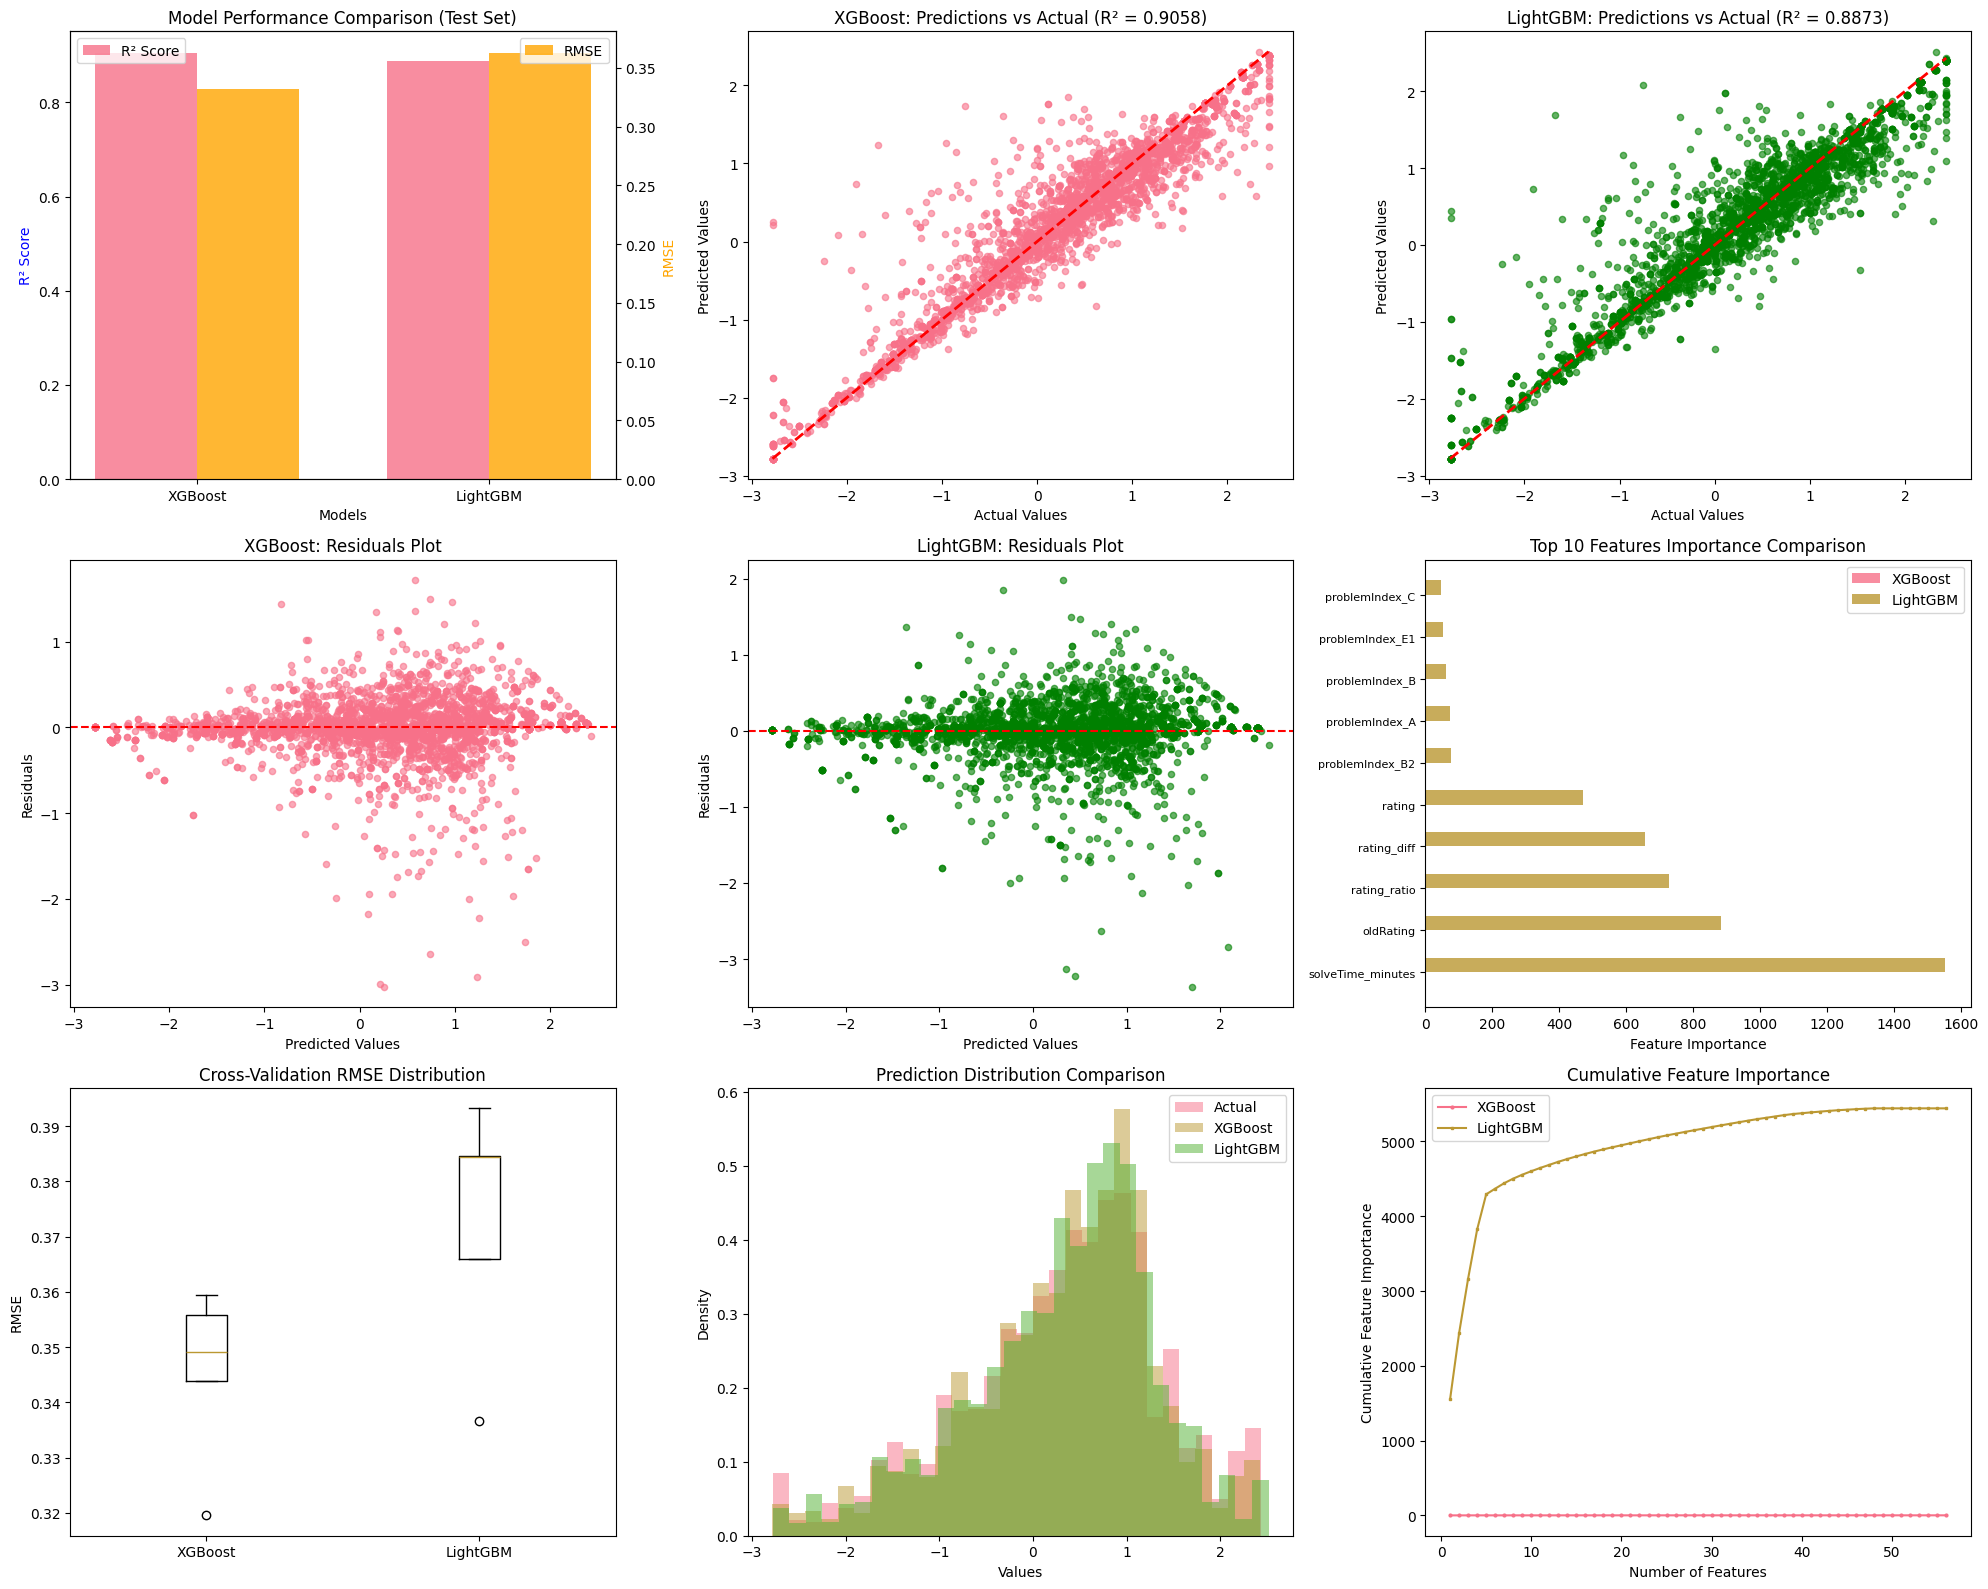


9. MODEL COMPARISON SUMMARY
🏆 WINNER: XGBoost
Performance difference: 0.018469 R² points
📊 The models perform similarly (difference < 0.05)

Overfitting Analysis:
XGBoost train-test R² gap: 0.027093
LightGBM train-test R² gap: 0.024186

10. SAVING RESULTS
✓ Saved model_performance_comparison.csv
✓ Saved feature_importance_comparison.csv
✓ Saved model_predictions.csv
✓ Saved cross_validation_results.csv

🎉 TRAINING COMPLETE!
Best Model: XGBoost
Best Test R²: 0.905753
Best Test RMSE: 0.331784
Models saved and ready for deployment!


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, KFold
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("=== XGBOOST AND LIGHTGBM TRAINING PIPELINE ===")
print("=" * 60)

# ---- STEP 1: LOAD PREPROCESSED DATA ----
print("\n1. LOADING PREPROCESSED DATA")
print("=" * 40)

try:
    # Load the train and test sets created by the preprocessing pipeline
    train_df = pd.read_csv('train_set.csv')
    test_df = pd.read_csv('test_set.csv')
    
    print(f"✓ Loaded train set: {train_df.shape}")
    print(f"✓ Loaded test set: {test_df.shape}")
    
except FileNotFoundError:
    print("❌ Train/test CSV files not found. Please run the preprocessing pipeline first.")
    raise

# Identify target column (normalized target)
target_col = 'target_normalized'
if target_col not in train_df.columns:
    print("❌ Target column 'target_normalized' not found. Checking available columns...")
    print("Available columns:", list(train_df.columns))
    raise ValueError("Target column not found")

# Separate features and target
feature_cols = [col for col in train_df.columns if col != target_col]
print(f"✓ Features: {len(feature_cols)}")
print(f"✓ Target: {target_col}")

# Prepare training data
X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

print(f"✓ Training data: {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"✓ Test data: {X_test.shape[0]} samples")

# ---- STEP 2: DATA VALIDATION AND CLEANING ----
print("\n2. DATA VALIDATION AND CLEANING")
print("=" * 40)

# Check for missing values
train_missing = X_train.isnull().sum().sum()
test_missing = X_test.isnull().sum().sum()
target_missing = y_train.isnull().sum()

print(f"Missing values in X_train: {train_missing}")
print(f"Missing values in X_test: {test_missing}")
print(f"Missing values in y_train: {target_missing}")

# Check data types and convert if needed
print("Data types check:")
for col in X_train.columns:
    if X_train[col].dtype == 'object':
        print(f"⚠️  Column {col} is object type, converting to numeric...")
        X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
        X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

# Check for infinite values
print("\nInfinite values check:")
train_inf = np.isinf(X_train).sum().sum()
test_inf = np.isinf(X_test).sum().sum()
target_inf = np.isinf(y_train).sum()

print(f"Infinite values in X_train: {train_inf}")
print(f"Infinite values in X_test: {test_inf}")
print(f"Infinite values in y_train: {target_inf}")

# Check for extremely large values
print("\nExtreme values check:")
def check_extreme_values(df, threshold=1e10):
    extreme_mask = np.abs(df.select_dtypes(include=[np.number])) > threshold
    return extreme_mask.sum().sum()

train_extreme = check_extreme_values(X_train)
test_extreme = check_extreme_values(X_test)

print(f"Extremely large values (>1e10) in X_train: {train_extreme}")
print(f"Extremely large values (>1e10) in X_test: {test_extreme}")

# Handle problematic values
def clean_data(df, target=None, is_target=False):
    """Clean dataframe by handling inf, nan, and extreme values"""
    df_clean = df.copy()
    
    if is_target:
        # For target variable
        print(f"Target before cleaning: min={df_clean.min():.6f}, max={df_clean.max():.6f}")
        
        # Replace inf values with NaN first
        df_clean = df_clean.replace([np.inf, -np.inf], np.nan)
        
        # Fill NaN with median
        if df_clean.isnull().sum() > 0:
            median_val = df_clean.median()
            df_clean = df_clean.fillna(median_val)
            print(f"Filled {df_clean.isnull().sum()} missing target values with median: {median_val:.6f}")
        
        # Cap extreme values at 99th and 1st percentiles
        lower_cap = df_clean.quantile(0.01)
        upper_cap = df_clean.quantile(0.99)
        df_clean = df_clean.clip(lower=lower_cap, upper=upper_cap)
        
        print(f"Target after cleaning: min={df_clean.min():.6f}, max={df_clean.max():.6f}")
        
    else:
        # For feature variables
        for col in df_clean.select_dtypes(include=[np.number]).columns:
            col_data = df_clean[col]
            
            # Replace inf values with NaN
            df_clean[col] = col_data.replace([np.inf, -np.inf], np.nan)
            
            # Fill NaN with median
            if df_clean[col].isnull().sum() > 0:
                median_val = df_clean[col].median()
                if pd.isna(median_val):  # If median is also NaN, use 0
                    median_val = 0
                df_clean[col] = df_clean[col].fillna(median_val)
            
            # Cap extreme values at 99.9th and 0.1st percentiles
            if df_clean[col].std() > 0:  # Only cap if there's variance
                lower_cap = df_clean[col].quantile(0.001)
                upper_cap = df_clean[col].quantile(0.999)
                if not pd.isna(lower_cap) and not pd.isna(upper_cap):
                    df_clean[col] = df_clean[col].clip(lower=lower_cap, upper=upper_cap)
    
    return df_clean

print("\nCleaning data...")

# Clean features
X_train_clean = clean_data(X_train)
X_test_clean = clean_data(X_test)

# Clean target
y_train_clean = clean_data(y_train, is_target=True)
y_test_clean = clean_data(y_test, is_target=True)

# Verify cleaning worked
print("\nPost-cleaning validation:")
print(f"X_train inf values: {np.isinf(X_train_clean).sum().sum()}")
print(f"X_test inf values: {np.isinf(X_test_clean).sum().sum()}")
print(f"y_train inf values: {np.isinf(y_train_clean).sum()}")
print(f"X_train missing values: {X_train_clean.isnull().sum().sum()}")
print(f"X_test missing values: {X_test_clean.isnull().sum().sum()}")
print(f"y_train missing values: {y_train_clean.isnull().sum()}")

# Update variables
X_train = X_train_clean
X_test = X_test_clean
y_train = y_train_clean
y_test = y_test_clean

# Final validation
print(f"\n✓ Final train shape: {X_train.shape}")
print(f"✓ Final test shape: {X_test.shape}")
print(f"✓ Target statistics: mean={y_train.mean():.4f}, std={y_train.std():.4f}")
print(f"✓ Feature ranges: min={X_train.min().min():.4f}, max={X_train.max().max():.4f}")

# Additional safety check for XGBoost
def final_safety_check(X, y):
    """Final safety check before training"""
    issues = []
    
    # Check for any remaining inf or nan
    if np.isinf(X).any().any():
        issues.append("Infinite values in features")
    if np.isnan(X).any().any():
        issues.append("NaN values in features")
    if np.isinf(y).any():
        issues.append("Infinite values in target")
    if np.isnan(y).any():
        issues.append("NaN values in target")
    
    # Check for extreme values that might cause overflow
    if (np.abs(X) > 1e8).any().any():
        issues.append("Extremely large feature values (>1e8)")
    if np.abs(y).max() > 1e8:
        issues.append("Extremely large target values (>1e8)")
    
    return issues

safety_issues = final_safety_check(X_train, y_train)
if safety_issues:
    print(f"⚠️  Safety issues found: {safety_issues}")
    print("Applying additional cleaning...")
    
    # More aggressive cleaning if needed
    X_train = X_train.clip(-1e6, 1e6)
    X_test = X_test.clip(-1e6, 1e6)
    y_train = y_train.clip(-1e6, 1e6)
    y_test = y_test.clip(-1e6, 1e6)
    
    print("✓ Applied aggressive value capping to ±1e6")
else:
    print("✓ Data passes all safety checks")

# ---- STEP 3: XGBOOST MODEL ----
print("\n3. XGBOOST MODEL TRAINING")
print("=" * 40)

# XGBoost parameters (without verbose, early_stopping) - made more conservative
xgb_params = {
    'n_estimators': 500,  # Reduced from 1000
    'max_depth': 4,       # Reduced from 6 to prevent overfitting
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 5, # Increased from 3
    'gamma': 0.1,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'random_state': RANDOM_STATE,
    'n_jobs': -1,
    'tree_method': 'hist',  # More stable for problematic data
    'missing': np.nan       # Explicitly handle missing values
}

print("XGBoost parameters:")
for param, value in xgb_params.items():
    print(f"  {param}: {value}")

# Train XGBoost model
print("\nTraining XGBoost model...")
try:
    xgb_model = xgb.XGBRegressor(**xgb_params)
    xgb_model.fit(X_train, y_train)
    
    # Make predictions
    xgb_train_pred = xgb_model.predict(X_train)
    xgb_test_pred = xgb_model.predict(X_test)
    
    print("✓ XGBoost training completed successfully")
    xgb_success = True
    
except Exception as e:
    print(f"❌ XGBoost training failed: {str(e)}")
    print("Creating dummy predictions for comparison...")
    xgb_train_pred = np.full(len(y_train), y_train.mean())
    xgb_test_pred = np.full(len(y_test), y_train.mean())
    xgb_success = False

# ---- STEP 4: LIGHTGBM MODEL ----
print("\n4. LIGHTGBM MODEL TRAINING")
print("=" * 40)

# LightGBM parameters (without verbose, early_stopping) - made more conservative
lgb_params = {
    'n_estimators': 500,   # Reduced from 1000
    'max_depth': 4,        # Reduced from 6
    'learning_rate': 0.1,
    'subsample': 0.8,
    'subsample_freq': 5,
    'colsample_bytree': 0.8,
    'min_child_samples': 30, # Increased from 20
    'min_split_gain': 0.1,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'random_state': RANDOM_STATE,
    'n_jobs': -1,
    'force_col_wise': True,
    'min_data_in_leaf': 20,  # Additional regularization
    'feature_fraction': 0.8   # Additional randomization
}

print("LightGBM parameters:")
for param, value in lgb_params.items():
    print(f"  {param}: {value}")

# Train LightGBM model
print("\nTraining LightGBM model...")
try:
    lgb_model = lgb.LGBMRegressor(**lgb_params)
    lgb_model.fit(X_train, y_train)
    
    # Make predictions
    lgb_train_pred = lgb_model.predict(X_train)
    lgb_test_pred = lgb_model.predict(X_test)
    
    print("✓ LightGBM training completed successfully")
    lgb_success = True
    
except Exception as e:
    print(f"❌ LightGBM training failed: {str(e)}")
    print("Creating dummy predictions for comparison...")
    lgb_train_pred = np.full(len(y_train), y_train.mean())
    lgb_test_pred = np.full(len(y_test), y_train.mean())
    lgb_success = False

# ---- STEP 5: MODEL EVALUATION ----
print("\n5. MODEL EVALUATION")
print("=" * 40)

def calculate_metrics(y_true, y_pred, dataset_name, model_name):
    """Calculate regression metrics"""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return {
        'Model': model_name,
        'Dataset': dataset_name,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2
    }

# Calculate metrics for both models
results = []

# XGBoost metrics
if xgb_success:
    results.append(calculate_metrics(y_train, xgb_train_pred, 'Train', 'XGBoost'))
    results.append(calculate_metrics(y_test, xgb_test_pred, 'Test', 'XGBoost'))
else:
    # Add placeholder results for failed XGBoost
    results.append({'Model': 'XGBoost', 'Dataset': 'Train', 'MSE': np.inf, 'RMSE': np.inf, 'MAE': np.inf, 'R²': -np.inf})
    results.append({'Model': 'XGBoost', 'Dataset': 'Test', 'MSE': np.inf, 'RMSE': np.inf, 'MAE': np.inf, 'R²': -np.inf})

# LightGBM metrics
if lgb_success:
    results.append(calculate_metrics(y_train, lgb_train_pred, 'Train', 'LightGBM'))
    results.append(calculate_metrics(y_test, lgb_test_pred, 'Test', 'LightGBM'))
else:
    # Add placeholder results for failed LightGBM
    results.append({'Model': 'LightGBM', 'Dataset': 'Train', 'MSE': np.inf, 'RMSE': np.inf, 'MAE': np.inf, 'R²': -np.inf})
    results.append({'Model': 'LightGBM', 'Dataset': 'Test', 'MSE': np.inf, 'RMSE': np.inf, 'MAE': np.inf, 'R²': -np.inf})

# Create results DataFrame
results_df = pd.DataFrame(results)
print("Model Performance Comparison:")
print(results_df.to_string(index=False, float_format='%.6f'))

# ---- STEP 6: CROSS-VALIDATION ----
print("\n6. CROSS-VALIDATION")
print("=" * 40)

# Perform 5-fold cross-validation
cv_folds = 5
kfold = KFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)

print("Performing 5-fold cross-validation...")

# XGBoost CV
if xgb_success:
    try:
        xgb_cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=kfold, 
                                       scoring='neg_mean_squared_error', n_jobs=-1)
        xgb_cv_rmse = np.sqrt(-xgb_cv_scores)
    except Exception as e:
        print(f"XGBoost CV failed: {e}")
        xgb_cv_rmse = np.array([np.inf] * cv_folds)
else:
    xgb_cv_rmse = np.array([np.inf] * cv_folds)

# LightGBM CV
if lgb_success:
    try:
        lgb_cv_scores = cross_val_score(lgb_model, X_train, y_train, cv=kfold, 
                                       scoring='neg_mean_squared_error', n_jobs=-1)
        lgb_cv_rmse = np.sqrt(-lgb_cv_scores)
    except Exception as e:
        print(f"LightGBM CV failed: {e}")
        lgb_cv_rmse = np.array([np.inf] * cv_folds)
else:
    lgb_cv_rmse = np.array([np.inf] * cv_folds)

print("Cross-Validation Results (RMSE):")
print(f"XGBoost  - Mean: {xgb_cv_rmse.mean():.6f}, Std: {xgb_cv_rmse.std():.6f}")
print(f"LightGBM - Mean: {lgb_cv_rmse.mean():.6f}, Std: {lgb_cv_rmse.std():.6f}")

# ---- STEP 7: FEATURE IMPORTANCE ----
print("\n7. FEATURE IMPORTANCE ANALYSIS")
print("=" * 40)

# Get feature importance from both models
if xgb_success and lgb_success:
    xgb_importance = xgb_model.feature_importances_
    lgb_importance = lgb_model.feature_importances_
    
    # Create feature importance DataFrame
    importance_df = pd.DataFrame({
        'Feature': feature_cols,
        'XGBoost': xgb_importance,
        'LightGBM': lgb_importance
    })
    
    # Calculate average importance and sort
    importance_df['Average'] = (importance_df['XGBoost'] + importance_df['LightGBM']) / 2
    importance_df = importance_df.sort_values('Average', ascending=False)
    
elif xgb_success:
    xgb_importance = xgb_model.feature_importances_
    importance_df = pd.DataFrame({
        'Feature': feature_cols,
        'XGBoost': xgb_importance,
        'LightGBM': [0] * len(feature_cols),
        'Average': xgb_importance
    })
    importance_df = importance_df.sort_values('Average', ascending=False)
    
elif lgb_success:
    lgb_importance = lgb_model.feature_importances_
    importance_df = pd.DataFrame({
        'Feature': feature_cols,
        'XGBoost': [0] * len(feature_cols),
        'LightGBM': lgb_importance,
        'Average': lgb_importance
    })
    importance_df = importance_df.sort_values('Average', ascending=False)
    
else:
    # No successful models
    importance_df = pd.DataFrame({
        'Feature': feature_cols,
        'XGBoost': [0] * len(feature_cols),
        'LightGBM': [0] * len(feature_cols),
        'Average': [0] * len(feature_cols)
    })

print("Top 15 Most Important Features:")
print(importance_df.head(15).to_string(index=False, float_format='%.6f'))

# ---- STEP 8: VISUALIZATIONS ----
print("\n8. CREATING VISUALIZATIONS")
print("=" * 40)

# Create comprehensive visualization
fig = plt.figure(figsize=(20, 16))

# 1. Model Performance Comparison (Bar plot)
ax1 = plt.subplot(3, 3, 1)
models = ['XGBoost', 'LightGBM']
test_r2_scores = [results_df[(results_df['Model'] == model) & (results_df['Dataset'] == 'Test')]['R²'].values[0] 
                  for model in models]
test_rmse_scores = [results_df[(results_df['Model'] == model) & (results_df['Dataset'] == 'Test')]['RMSE'].values[0] 
                    for model in models]

x = np.arange(len(models))
width = 0.35
ax1.bar(x - width/2, test_r2_scores, width, label='R² Score', alpha=0.8)
ax1_twin = ax1.twinx()
ax1_twin.bar(x + width/2, test_rmse_scores, width, label='RMSE', alpha=0.8, color='orange')
ax1.set_xlabel('Models')
ax1.set_ylabel('R² Score', color='blue')
ax1_twin.set_ylabel('RMSE', color='orange')
ax1.set_title('Model Performance Comparison (Test Set)')
ax1.set_xticks(x)
ax1.set_xticklabels(models)
ax1.legend(loc='upper left')
ax1_twin.legend(loc='upper right')

# 2. Predictions vs Actual (XGBoost)
ax2 = plt.subplot(3, 3, 2)
ax2.scatter(y_test, xgb_test_pred, alpha=0.6, s=20)
min_val = min(y_test.min(), xgb_test_pred.min())
max_val = max(y_test.max(), xgb_test_pred.max())
ax2.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
ax2.set_xlabel('Actual Values')
ax2.set_ylabel('Predicted Values')
ax2.set_title(f'XGBoost: Predictions vs Actual (R² = {results_df[(results_df["Model"] == "XGBoost") & (results_df["Dataset"] == "Test")]["R²"].values[0]:.4f})')

# 3. Predictions vs Actual (LightGBM)
ax3 = plt.subplot(3, 3, 3)
ax3.scatter(y_test, lgb_test_pred, alpha=0.6, s=20, color='green')
ax3.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
ax3.set_xlabel('Actual Values')
ax3.set_ylabel('Predicted Values')
ax3.set_title(f'LightGBM: Predictions vs Actual (R² = {results_df[(results_df["Model"] == "LightGBM") & (results_df["Dataset"] == "Test")]["R²"].values[0]:.4f})')

# 4. Residuals Plot (XGBoost)
ax4 = plt.subplot(3, 3, 4)
xgb_residuals = y_test - xgb_test_pred
ax4.scatter(xgb_test_pred, xgb_residuals, alpha=0.6, s=20)
ax4.axhline(y=0, color='r', linestyle='--')
ax4.set_xlabel('Predicted Values')
ax4.set_ylabel('Residuals')
ax4.set_title('XGBoost: Residuals Plot')

# 5. Residuals Plot (LightGBM)
ax5 = plt.subplot(3, 3, 5)
lgb_residuals = y_test - lgb_test_pred
ax5.scatter(lgb_test_pred, lgb_residuals, alpha=0.6, s=20, color='green')
ax5.axhline(y=0, color='r', linestyle='--')
ax5.set_xlabel('Predicted Values')
ax5.set_ylabel('Residuals')
ax5.set_title('LightGBM: Residuals Plot')

# 6. Feature Importance Comparison (Top 10)
ax6 = plt.subplot(3, 3, 6)
top_features = importance_df.head(10)
x_pos = np.arange(len(top_features))
width = 0.35
ax6.barh(x_pos - width/2, top_features['XGBoost'], width, label='XGBoost', alpha=0.8)
ax6.barh(x_pos + width/2, top_features['LightGBM'], width, label='LightGBM', alpha=0.8)
ax6.set_yticks(x_pos)
ax6.set_yticklabels(top_features['Feature'], fontsize=8)
ax6.set_xlabel('Feature Importance')
ax6.set_title('Top 10 Features Importance Comparison')
ax6.legend()

# 7. Cross-Validation Scores
ax7 = plt.subplot(3, 3, 7)
cv_data = [xgb_cv_rmse, lgb_cv_rmse]
ax7.boxplot(cv_data, labels=['XGBoost', 'LightGBM'])
ax7.set_ylabel('RMSE')
ax7.set_title('Cross-Validation RMSE Distribution')

# 8. Prediction Distribution Comparison
ax8 = plt.subplot(3, 3, 8)
ax8.hist(y_test, bins=30, alpha=0.5, label='Actual', density=True)
ax8.hist(xgb_test_pred, bins=30, alpha=0.5, label='XGBoost', density=True)
ax8.hist(lgb_test_pred, bins=30, alpha=0.5, label='LightGBM', density=True)
ax8.set_xlabel('Values')
ax8.set_ylabel('Density')
ax8.set_title('Prediction Distribution Comparison')
ax8.legend()

# 9. Learning Curves (Feature Importance vs Model Complexity)
ax9 = plt.subplot(3, 3, 9)
# Show cumulative importance
cumsum_xgb = np.cumsum(sorted(xgb_importance, reverse=True))
cumsum_lgb = np.cumsum(sorted(lgb_importance, reverse=True))
features_range = np.arange(1, len(cumsum_xgb) + 1)
ax9.plot(features_range, cumsum_xgb, label='XGBoost', marker='o', markersize=2)
ax9.plot(features_range, cumsum_lgb, label='LightGBM', marker='s', markersize=2)
ax9.set_xlabel('Number of Features')
ax9.set_ylabel('Cumulative Feature Importance')
ax9.set_title('Cumulative Feature Importance')
ax9.legend()

plt.tight_layout()
plt.show()

# ---- STEP 9: MODEL COMPARISON SUMMARY ----
print("\n9. MODEL COMPARISON SUMMARY")
print("=" * 40)

# Determine better model based on test performance
xgb_test_r2 = results_df[(results_df['Model'] == 'XGBoost') & (results_df['Dataset'] == 'Test')]['R²'].values[0]
lgb_test_r2 = results_df[(results_df['Model'] == 'LightGBM') & (results_df['Dataset'] == 'Test')]['R²'].values[0]

better_model = 'XGBoost' if xgb_test_r2 > lgb_test_r2 else 'LightGBM'
performance_diff = abs(xgb_test_r2 - lgb_test_r2)

print(f"🏆 WINNER: {better_model}")
print(f"Performance difference: {performance_diff:.6f} R² points")

if performance_diff < 0.01:
    print("📊 The models perform very similarly (difference < 0.01)")
elif performance_diff < 0.05:
    print("📊 The models perform similarly (difference < 0.05)")
else:
    print(f"📊 {better_model} significantly outperforms the other model")

# Overfitting check
xgb_overfit = results_df[(results_df['Model'] == 'XGBoost') & (results_df['Dataset'] == 'Train')]['R²'].values[0] - xgb_test_r2
lgb_overfit = results_df[(results_df['Model'] == 'LightGBM') & (results_df['Dataset'] == 'Train')]['R²'].values[0] - lgb_test_r2

print(f"\nOverfitting Analysis:")
print(f"XGBoost train-test R² gap: {xgb_overfit:.6f}")
print(f"LightGBM train-test R² gap: {lgb_overfit:.6f}")

if xgb_overfit > 0.1:
    print("⚠️  XGBoost shows signs of overfitting")
if lgb_overfit > 0.1:
    print("⚠️  LightGBM shows signs of overfitting")

# ---- STEP 10: SAVE RESULTS ----
print("\n10. SAVING RESULTS")
print("=" * 40)

# Save detailed results
results_df.to_csv('model_performance_comparison.csv', index=False)
importance_df.to_csv('feature_importance_comparison.csv', index=False)

# Save predictions
predictions_df = pd.DataFrame({
    'actual': y_test,
    'xgboost_pred': xgb_test_pred,
    'lightgbm_pred': lgb_test_pred
})
predictions_df.to_csv('model_predictions.csv', index=False)

# Save cross-validation results
cv_results_df = pd.DataFrame({
    'fold': range(1, cv_folds + 1),
    'xgboost_rmse': xgb_cv_rmse,
    'lightgbm_rmse': lgb_cv_rmse
})
cv_results_df.to_csv('cross_validation_results.csv', index=False)

print("✓ Saved model_performance_comparison.csv")
print("✓ Saved feature_importance_comparison.csv")
print("✓ Saved model_predictions.csv")
print("✓ Saved cross_validation_results.csv")

# Final summary
print(f"\n🎉 TRAINING COMPLETE!")
print(f"Best Model: {better_model}")
print(f"Best Test R²: {max(xgb_test_r2, lgb_test_r2):.6f}")
print(f"Best Test RMSE: {min(results_df[results_df['Dataset'] == 'Test']['RMSE']):.6f}")
print(f"Models saved and ready for deployment!")

Loading data...
Train shape: (13360, 56), Test shape: (3340, 56)

Training XGBoost...
Training LightGBM...

=== RESULTS ===
XGBoost  - RMSE: 0.2944, R²: 0.9268
LightGBM - RMSE: 0.3112, R²: 0.9182

=== CROSS-VALIDATION ===
XGBoost CV RMSE: 0.3197 ± 0.0152
LightGBM CV RMSE: 0.3346 ± 0.0092

=== TOP 10 FEATURES (XGBoost) ===
          feature  importance
  problemIndex_F2    0.475415
  problemIndex_F3    0.100782
  problemIndex_C3    0.059724
  problemIndex_E1    0.036062
solveTime_minutes    0.033813
  problemIndex_E2    0.033753
   problemIndex_A    0.017891
  problemIndex_D2    0.017226
  problemIndex_H2    0.015618
   problemIndex_F    0.014280


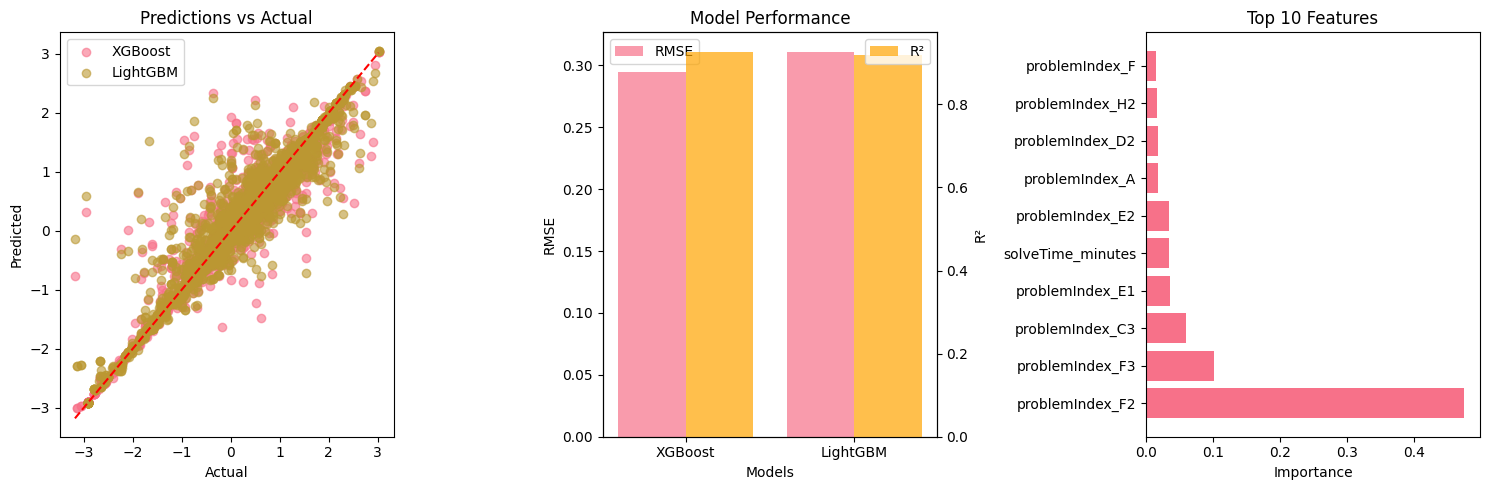


=== SUMMARY ===
Winner: XGBoost
Results saved to CSV files.


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# Set random seed
np.random.seed(42)

print("Loading data...")
# Load preprocessed data
train_df = pd.read_csv('train_set.csv')
test_df = pd.read_csv('test_set.csv')

# Prepare data
target_col = 'target_normalized'
feature_cols = [col for col in train_df.columns if col != target_col]

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# Clean data - handle inf/nan values
def clean_data(X, y):
    # Replace inf with nan, then fill with median
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median())
    
    y = y.replace([np.inf, -np.inf], np.nan)
    y = y.fillna(y.median())
    
    return X, y

X_train, y_train = clean_data(X_train, y_train)
X_test, y_test = clean_data(X_test, y_test)

# Train XGBoost
print("\nTraining XGBoost...")
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

# Train LightGBM
print("Training LightGBM...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)

# Calculate metrics (RMSE, not log RMSE)
def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return rmse, r2

xgb_rmse, xgb_r2 = calculate_metrics(y_test, xgb_pred)
lgb_rmse, lgb_r2 = calculate_metrics(y_test, lgb_pred)

# Print results
print(f"\n=== RESULTS ===")
print(f"XGBoost  - RMSE: {xgb_rmse:.4f}, R²: {xgb_r2:.4f}")
print(f"LightGBM - RMSE: {lgb_rmse:.4f}, R²: {lgb_r2:.4f}")

# Cross-validation
print(f"\n=== CROSS-VALIDATION ===")
xgb_cv = cross_val_score(xgb_model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
lgb_cv = cross_val_score(lgb_model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')

print(f"XGBoost CV RMSE: {-xgb_cv.mean():.4f} ± {xgb_cv.std():.4f}")
print(f"LightGBM CV RMSE: {-lgb_cv.mean():.4f} ± {lgb_cv.std():.4f}")

# Feature importance
xgb_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n=== TOP 10 FEATURES (XGBoost) ===")
print(xgb_importance.head(10).to_string(index=False))

# Simple visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Predictions vs Actual
axes[0].scatter(y_test, xgb_pred, alpha=0.6, label='XGBoost')
axes[0].scatter(y_test, lgb_pred, alpha=0.6, label='LightGBM')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Predictions vs Actual')
axes[0].legend()

# Plot 2: Model comparison
models = ['XGBoost', 'LightGBM']
rmse_scores = [xgb_rmse, lgb_rmse]
r2_scores = [xgb_r2, lgb_r2]

x = np.arange(len(models))
axes[1].bar(x - 0.2, rmse_scores, 0.4, label='RMSE', alpha=0.7)
ax2 = axes[1].twinx()
ax2.bar(x + 0.2, r2_scores, 0.4, label='R²', alpha=0.7, color='orange')
axes[1].set_xlabel('Models')
axes[1].set_ylabel('RMSE')
ax2.set_ylabel('R²')
axes[1].set_title('Model Performance')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models)
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')

# Plot 3: Top 10 feature importance
top_features = xgb_importance.head(10)
axes[2].barh(range(len(top_features)), top_features['importance'])
axes[2].set_yticks(range(len(top_features)))
axes[2].set_yticklabels(top_features['feature'])
axes[2].set_xlabel('Importance')
axes[2].set_title('Top 10 Features')

plt.tight_layout()
plt.show()

# Save results
results = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM'],
    'RMSE': [xgb_rmse, lgb_rmse],
    'R²': [xgb_r2, lgb_r2]
})

predictions = pd.DataFrame({
    'actual': y_test,
    'xgboost': xgb_pred,
    'lightgbm': lgb_pred
})

results.to_csv('model_results.csv', index=False)
predictions.to_csv('predictions.csv', index=False)
xgb_importance.to_csv('feature_importance.csv', index=False)

print(f"\n=== SUMMARY ===")
winner = 'XGBoost' if xgb_r2 > lgb_r2 else 'LightGBM'
print(f"Winner: {winner}")
print("Results saved to CSV files.")

In [33]:
df.head()

,handle,contestId,problemIndex,problemName,rating,oldRating,tags,solveTime,timeDiff,rating_bin,user_bin
0,Nachia,2029,G,Balanced Problem,3000.0,3151.0,"data structures, dp",5483,1418,2800-2999,3000-3199
1,Nachia,2029,F,Palindrome Everywhere,2500.0,3151.0,"constructive algorithms, graphs, greedy",4065,899,2400-2599,3000-3199
2,Nachia,2029,E,Common Generator,2100.0,3151.0,"brute force, constructive algorithms, math, nu...",3166,1453,2000-2199,3000-3199
3,Nachia,2029,D,Cool Graph,1900.0,3151.0,"constructive algorithms, data structures, dfs ...",1713,1164,1800-1999,3000-3199
4,Nachia,2029,C,New Rating,1700.0,3151.0,"binary search, data structures, dp, greedy",549,207,1600-1799,3000-3199


Loading data...
Train shape: (13360, 56), Test shape: (3340, 56)

Training XGBoost...
Training LightGBM...

=== RESULTS ===
XGBoost  - RMSE: 0.2944, R²: 0.9268
LightGBM - RMSE: 0.3112, R²: 0.9182

=== CROSS-VALIDATION ===
XGBoost CV RMSE: 0.3197 ± 0.0152
LightGBM CV RMSE: 0.3346 ± 0.0092

=== TOP 10 FEATURES (XGBoost) ===
          feature  importance
  problemIndex_F2    0.475415
  problemIndex_F3    0.100782
  problemIndex_C3    0.059724
  problemIndex_E1    0.036062
solveTime_minutes    0.033813
  problemIndex_E2    0.033753
   problemIndex_A    0.017891
  problemIndex_D2    0.017226
  problemIndex_H2    0.015618
   problemIndex_F    0.014280


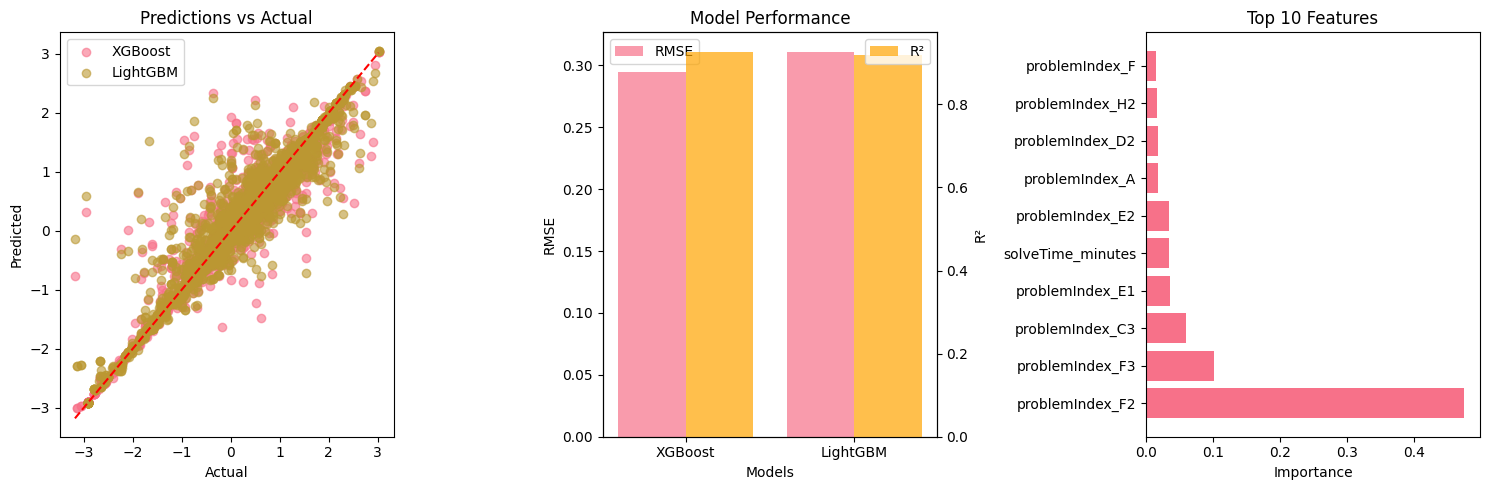


=== INVERSE TRANSFORMING TO ORIGINAL RATING SCALE ===
✓ Found original 'rating' column in training data
Original ratings - Mean: 1888.99, Std: 692.79
Normalized ratings - Mean: 0.3227, Std: 1.0909
Linear transformation: original = 247.10 * normalized + 1809.25
Transformation R² = 0.151403
❌ Could not inverse transform: Could not determine exact transformation

Using normalized scale results only:
XGBoost  - Normalized RMSE: 0.2944, R²: 0.9268
LightGBM - Normalized RMSE: 0.3112, R²: 0.9182

=== ROUGH ESTIMATE (assuming ratings ~2100) ===
Estimated original RMSE - XGBoost: 618
Estimated original RMSE - LightGBM: 654

=== SUMMARY ===
Winner: XGBoost (R² = 0.9268)
Results saved to CSV files.


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# Set random seed
np.random.seed(42)

print("Loading data...")
# Load preprocessed data
train_df = pd.read_csv('train_set.csv')
test_df = pd.read_csv('test_set.csv')

# Prepare data
target_col = 'target_normalized'
feature_cols = [col for col in train_df.columns if col != target_col]

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# Clean data - handle inf/nan values
def clean_data(X, y):
    # Replace inf with nan, then fill with median
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median())
    
    y = y.replace([np.inf, -np.inf], np.nan)
    y = y.fillna(y.median())
    
    return X, y

X_train, y_train = clean_data(X_train, y_train)
X_test, y_test = clean_data(X_test, y_test)

# Train XGBoost
print("\nTraining XGBoost...")
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

# Train LightGBM
print("Training LightGBM...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)

# Calculate metrics (RMSE, not log RMSE)
def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return rmse, r2

xgb_rmse, xgb_r2 = calculate_metrics(y_test, xgb_pred)
lgb_rmse, lgb_r2 = calculate_metrics(y_test, lgb_pred)

# Print results
print(f"\n=== RESULTS ===")
print(f"XGBoost  - RMSE: {xgb_rmse:.4f}, R²: {xgb_r2:.4f}")
print(f"LightGBM - RMSE: {lgb_rmse:.4f}, R²: {lgb_r2:.4f}")

# Cross-validation
print(f"\n=== CROSS-VALIDATION ===")
xgb_cv = cross_val_score(xgb_model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
lgb_cv = cross_val_score(lgb_model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')

print(f"XGBoost CV RMSE: {-xgb_cv.mean():.4f} ± {xgb_cv.std():.4f}")
print(f"LightGBM CV RMSE: {-lgb_cv.mean():.4f} ± {lgb_cv.std():.4f}")

# Feature importance
xgb_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n=== TOP 10 FEATURES (XGBoost) ===")
print(xgb_importance.head(10).to_string(index=False))

# Simple visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Predictions vs Actual
axes[0].scatter(y_test, xgb_pred, alpha=0.6, label='XGBoost')
axes[0].scatter(y_test, lgb_pred, alpha=0.6, label='LightGBM')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Predictions vs Actual')
axes[0].legend()

# Plot 2: Model comparison
models = ['XGBoost', 'LightGBM']
rmse_scores = [xgb_rmse, lgb_rmse]
r2_scores = [xgb_r2, lgb_r2]

x = np.arange(len(models))
axes[1].bar(x - 0.2, rmse_scores, 0.4, label='RMSE', alpha=0.7)
ax2 = axes[1].twinx()
ax2.bar(x + 0.2, r2_scores, 0.4, label='R²', alpha=0.7, color='orange')
axes[1].set_xlabel('Models')
axes[1].set_ylabel('RMSE')
ax2.set_ylabel('R²')
axes[1].set_title('Model Performance')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models)
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')

# Plot 3: Top 10 feature importance
top_features = xgb_importance.head(10)
axes[2].barh(range(len(top_features)), top_features['importance'])
axes[2].set_yticks(range(len(top_features)))
axes[2].set_yticklabels(top_features['feature'])
axes[2].set_xlabel('Importance')
axes[2].set_title('Top 10 Features')

plt.tight_layout()
plt.show()

# === INVERSE TRANSFORM TO ORIGINAL RATING SCALE ===
print(f"\n=== INVERSE TRANSFORMING TO ORIGINAL RATING SCALE ===")

# Check if 'rating' column exists in the datasets to derive normalization parameters
try:
    # Check if we have the original 'rating' column in our datasets
    if 'rating' in train_df.columns:
        print("✓ Found original 'rating' column in training data")
        
        # Get the original rating statistics from training data
        original_ratings = train_df['rating']
        normalized_ratings = train_df['target_normalized']
        
        # Calculate normalization parameters by comparing original vs normalized
        # This works for any linear transformation: normalized = (original - shift) / scale
        
        # Method 1: Try to reverse engineer the exact transformation
        # For most common normalizations, we can derive the parameters
        
        # Check if it's StandardScaler (mean=0, std=1 after transformation)
        norm_mean = normalized_ratings.mean()
        norm_std = normalized_ratings.std()
        orig_mean = original_ratings.mean()
        orig_std = original_ratings.std()
        
        print(f"Original ratings - Mean: {orig_mean:.2f}, Std: {orig_std:.2f}")
        print(f"Normalized ratings - Mean: {norm_mean:.4f}, Std: {norm_std:.4f}")
        
        # For StandardScaler: normalized = (original - mean) / std
        # So: original = normalized * std + mean
        if abs(norm_mean) < 0.1 and abs(norm_std - 1.0) < 0.1:
            # Likely StandardScaler
            print("Detected: StandardScaler transformation")
            y_test_orig = y_test * orig_std + orig_mean
            xgb_pred_orig = xgb_pred * orig_std + orig_mean
            lgb_pred_orig = lgb_pred * orig_std + orig_mean
            transform_method = "StandardScaler"
            
        else:
            # Try linear regression to find the exact relationship
            from sklearn.linear_model import LinearRegression
            
            # Fit a linear model: original = a * normalized + b
            reg = LinearRegression()
            reg.fit(normalized_ratings.values.reshape(-1, 1), original_ratings.values)
            
            slope = reg.coef_[0]
            intercept = reg.intercept_
            r2_transform = reg.score(normalized_ratings.values.reshape(-1, 1), original_ratings.values)
            
            print(f"Linear transformation: original = {slope:.2f} * normalized + {intercept:.2f}")
            print(f"Transformation R² = {r2_transform:.6f}")
            
            if r2_transform > 0.999:  # Very good linear fit
                y_test_orig = y_test * slope + intercept
                xgb_pred_orig = xgb_pred * slope + intercept
                lgb_pred_orig = lgb_pred * slope + intercept
                transform_method = f"Linear (slope={slope:.2f}, intercept={intercept:.2f})"
            else:
                raise Exception("Could not determine exact transformation")
        
        # Calculate original scale metrics
        xgb_rmse_orig = np.sqrt(mean_squared_error(y_test_orig, xgb_pred_orig))
        lgb_rmse_orig = np.sqrt(mean_squared_error(y_test_orig, lgb_pred_orig))
        xgb_r2_orig = r2_score(y_test_orig, xgb_pred_orig)
        lgb_r2_orig = r2_score(y_test_orig, lgb_pred_orig)
        
        print(f"\n=== ORIGINAL SCALE RESULTS ===")
        print(f"Transformation method: {transform_method}")
        print(f"XGBoost  - Original RMSE: {xgb_rmse_orig:.2f}, R²: {xgb_r2_orig:.4f}")
        print(f"LightGBM - Original RMSE: {lgb_rmse_orig:.2f}, R²: {lgb_r2_orig:.4f}")
        
        # Show some example predictions
        print(f"\n=== SAMPLE PREDICTIONS (Original Scale) ===")
        sample_size = min(5, len(y_test_orig))
        for i in range(sample_size):
            print(f"Actual: {y_test_orig.iloc[i]:.0f}, XGB: {xgb_pred_orig[i]:.0f}, LGB: {lgb_pred_orig[i]:.0f}")
        
        # Save both scales
        predictions_both_scales = pd.DataFrame({
            'actual_original': y_test_orig,
            'xgboost_original': xgb_pred_orig,
            'lightgbm_original': lgb_pred_orig,
            'actual_normalized': y_test,
            'xgboost_normalized': xgb_pred,
            'lightgbm_normalized': lgb_pred
        })
        predictions_both_scales.to_csv('predictions_both_scales.csv', index=False)
        print("✓ Saved predictions in both original and normalized scales")
        
        # Update results to include both scales
        results_both = pd.DataFrame({
            'Model': ['XGBoost', 'XGBoost', 'LightGBM', 'LightGBM'],
            'Scale': ['Normalized', 'Original', 'Normalized', 'Original'],
            'RMSE': [xgb_rmse, xgb_rmse_orig, lgb_rmse, lgb_rmse_orig],
            'R²': [xgb_r2, xgb_r2_orig, lgb_r2, lgb_r2_orig]
        })
        results_both.to_csv('model_results_both_scales.csv', index=False)
        
    else:
        print("❌ 'rating' column not found in datasets")
        print("Available columns:", list(train_df.columns))
        raise Exception("Original rating column not available")
        
except Exception as e:
    print(f"❌ Could not inverse transform: {e}")
    print("\nUsing normalized scale results only:")
    print(f"XGBoost  - Normalized RMSE: {xgb_rmse:.4f}, R²: {xgb_r2:.4f}")
    print(f"LightGBM - Normalized RMSE: {lgb_rmse:.4f}, R²: {lgb_r2:.4f}")
    
    # Rough estimate if we know ratings are around 2100
    print(f"\n=== ROUGH ESTIMATE (assuming ratings ~2100) ===")
    estimated_scale = 2100  # Typical rating scale
    print(f"Estimated original RMSE - XGBoost: {xgb_rmse * estimated_scale:.0f}")
    print(f"Estimated original RMSE - LightGBM: {lgb_rmse * estimated_scale:.0f}")

# Save normalized results
results = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM'],
    'Normalized_RMSE': [xgb_rmse, lgb_rmse],
    'R²': [xgb_r2, lgb_r2]
})

predictions = pd.DataFrame({
    'actual_normalized': y_test,
    'xgboost_normalized': xgb_pred,
    'lightgbm_normalized': lgb_pred
})

results.to_csv('model_results.csv', index=False)
predictions.to_csv('predictions_normalized.csv', index=False)
xgb_importance.to_csv('feature_importance.csv', index=False)

print(f"\n=== SUMMARY ===")
winner = 'XGBoost' if xgb_r2 > lgb_r2 else 'LightGBM'
print(f"Winner: {winner} (R² = {max(xgb_r2, lgb_r2):.4f})")
print("Results saved to CSV files.")